In [1]:

import os
import sys
import torch
import gc
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel , AutoModelForCausalLM
from pathlib import Path
import json
import numpy as np
from collections import defaultdict
import subprocess
import re


print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Number of GPUs:", torch.cuda.device_count())
    
    device = torch.device("cuda")
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
        print(
            "GPU memory (GB):",
            round(
                torch.cuda.get_device_properties(i).total_memory
                / (1024 ** 3),
                2
            )
        )
torch.cuda.empty_cache()
gc.collect()

print("free memory:")
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.memory_allocated(i)/1024**3:.2f} GB used")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu128
CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU memory (GB): 14.56
GPU 1: Tesla T4
GPU memory (GB): 14.56
free memory:
GPU 0: 0.00 GB used
GPU 1: 0.00 GB used


In [2]:

input_dir = "/kaggle/input"

print("Input directory exists:", os.path.exists(input_dir))

for root, dirs, files in os.walk(input_dir):
    for file in files:
        print(os.path.join(root, file))


Input directory exists: True
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/LICENSE_AND_ATTRIBUTION.txt
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/README.txt
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/corpus.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/example_predict.py
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/kg_subset_passages.txt
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/labels_dev.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_dev.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_hidden.jsonl
/kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/score.py


In [3]:

def find_unique_file(filename):
    matches = list(Path("/kaggle/input").rglob(filename))

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one {filename}, found {len(matches)}. "
            "Check the paths printed in the previous cell."
        )

    return matches[0]

CORPUS_PATH = find_unique_file("corpus.jsonl")
QUESTIONS_PATH = find_unique_file("questions_dev.jsonl")
LABELS_PATH = find_unique_file("labels_dev.jsonl")
QUESTIONS_HIDDEN_PATH = find_unique_file("questions_hidden.jsonl")
SCORE_PATH = find_unique_file("score.py")

print("Corpus:", CORPUS_PATH)
print("Questions:", QUESTIONS_PATH)
print("Labels:", LABELS_PATH)
print("Questions Hidden:", QUESTIONS_HIDDEN_PATH)
print("Score:", SCORE_PATH)

Corpus: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/corpus.jsonl
Questions: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_dev.jsonl
Labels: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/labels_dev.jsonl
Questions Hidden: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/questions_hidden.jsonl
Sorce: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1/score.py


In [4]:

def read_jsonl(path):
    rows = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))

    return rows

corpus = read_jsonl(CORPUS_PATH)
questions = read_jsonl(QUESTIONS_PATH)
labels = read_jsonl(LABELS_PATH)
questions_hidden = read_jsonl(QUESTIONS_HIDDEN_PATH)


print("Number of documents:", len(corpus))
print("Number of dev questions:", len(questions))
print("Number of dev labels:", len(labels))
print("Number of questions hidden:", len(questions_hidden))


print("\nFirst document:")
print(corpus[0])

print("\nFirst question:")
print(questions[0])

print("\nFirst label:")
print(labels[0])

print("\nFirst question hidden:")
print(questions_hidden[0])



Number of documents: 3882
Number of dev questions: 300
Number of dev labels: 300
Number of questions hidden: 300

First document:
{'doc_id': 'p00001', 'sentences': ['Fannā (Panāh) Khusraw , better known by his laqab of ʿAḍud al-Dawla ("Pillar of the [Abbasid] Dynasty")', '(September 24, 936 – March 26, 983) was an emir of the Buyid dynasty, ruling from 949 to 983, and at his height of power ruling an empire stretching from Makran as far to Yemen and the shores of the Mediterranean Sea.', 'He is widely regarded as the greatest monarch of the dynasty, and by the end of his reign was the most powerful ruler in the Middle East.', 'The son of Rukn al-Dawla, Fanna Khusraw was given the title of Adud al-Dawla by the Abbasid caliph in 948 when he was made emir of Fars after the death of his childless uncle', 'Imad al-Dawla, after which Rukn al-Dawla became the senior emir of the Buyids.', 'In 974 Adud al-Dawla was sent by his father to save his cousin Izz al-Dawla from a rebellion.', 'After de

In [5]:

doc_ids = []
doc_texts = []

for item in corpus:
    doc_id = item["doc_id"]
    title = item.get("title", "").strip()
    text = item.get("text", "").strip()

    if not text:
        text = " ".join(item.get("sentences", [])).strip()

    if not text:
        continue

    formatted_text = f"Title: {title}\nPassage: {text}"

    doc_ids.append(doc_id)
    doc_texts.append(formatted_text)

print("Documents prepared:", len(doc_texts))
print("\nExample input to embedding model:")
print(doc_texts[0])

print("\nUnique document IDs:", len(set(doc_ids)))
print("Duplicate document IDs:", len(doc_ids) - len(set(doc_ids)))

Documents prepared: 3882

Example input to embedding model:
Title: 'Adud al-Dawla
Passage: Fannā (Panāh) Khusraw , better known by his laqab of ʿAḍud al-Dawla ("Pillar of the [Abbasid] Dynasty") (September 24, 936 – March 26, 983) was an emir of the Buyid dynasty, ruling from 949 to 983, and at his height of power ruling an empire stretching from Makran as far to Yemen and the shores of the Mediterranean Sea. He is widely regarded as the greatest monarch of the dynasty, and by the end of his reign was the most powerful ruler in the Middle East. The son of Rukn al-Dawla, Fanna Khusraw was given the title of Adud al-Dawla by the Abbasid caliph in 948 when he was made emir of Fars after the death of his childless uncle Imad al-Dawla, after which Rukn al-Dawla became the senior emir of the Buyids. In 974 Adud al-Dawla was sent by his father to save his cousin Izz al-Dawla from a rebellion. After defeating the rebel forces, he claimed the emirate of Iraq for himself, and forced his cousin t

In [6]:


EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-4B"

tokenizer = AutoTokenizer.from_pretrained(
    EMBEDDING_MODEL_NAME,
    padding_side="left",
)

model = AutoModel.from_pretrained(
    EMBEDDING_MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
    max_memory={
        0: "14GiB",
        1: "14GiB",
        "cpu": "48GiB",
    },
)

model.eval()

print("Model loaded")
print("Device map:", model.hf_device_map)

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.26k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors.index.json:   0%|          | 0.00/30.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Model loaded
Device map: {'embed_tokens': 0, 'layers.0': 0, 'layers.1': 0, 'layers.2': 0, 'layers.3': 0, 'layers.4': 0, 'layers.5': 0, 'layers.6': 0, 'layers.7': 0, 'layers.8': 0, 'layers.9': 0, 'layers.10': 0, 'layers.11': 0, 'layers.12': 0, 'layers.13': 0, 'layers.14': 0, 'layers.15': 0, 'layers.16': 1, 'layers.17': 1, 'layers.18': 1, 'layers.19': 1, 'layers.20': 1, 'layers.21': 1, 'layers.22': 1, 'layers.23': 1, 'layers.24': 1, 'layers.25': 1, 'layers.26': 1, 'layers.27': 1, 'layers.28': 1, 'layers.29': 1, 'layers.30': 1, 'layers.31': 1, 'layers.32': 1, 'layers.33': 1, 'layers.34': 1, 'layers.35': 1, 'norm': 1, 'rotary_emb': 1}


In [7]:
@torch.inference_mode()
def make_embeddings(texts, batch_size=2, max_length=1024):
    all_embeddings = []

    input_device = model.get_input_embeddings().weight.device

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )

        inputs = {
            key: value.to(input_device)
            for key, value in inputs.items()
        }

        outputs = model(
            **inputs,
            use_cache=False,
            return_dict=True,
        )

        hidden = outputs.last_hidden_state

        embeddings = hidden[:, -1, :]

        embeddings = F.normalize(embeddings.float(), p=2, dim=1)

        all_embeddings.append(embeddings.cpu())

        del inputs, outputs, hidden, embeddings 

    return torch.cat(all_embeddings, dim=0).numpy()

In [8]:

test_texts = [
    "Title: Example Airport\nPassage: This is a test document.",
    "Title: Example Movie\nPassage: This movie originated in Pakistan.",
]

test_embeddings = make_embeddings(test_texts, batch_size=2)

print("Shape:", test_embeddings.shape)
print("All finite:", np.isfinite(test_embeddings).all())
print("Norms:", np.linalg.norm(test_embeddings, axis=1))
print("Device map:", model.hf_device_map)

Shape: (2, 2560)
All finite: True
Norms: [1. 1.]
Device map: {'embed_tokens': 0, 'layers.0': 0, 'layers.1': 0, 'layers.2': 0, 'layers.3': 0, 'layers.4': 0, 'layers.5': 0, 'layers.6': 0, 'layers.7': 0, 'layers.8': 0, 'layers.9': 0, 'layers.10': 0, 'layers.11': 0, 'layers.12': 0, 'layers.13': 0, 'layers.14': 0, 'layers.15': 0, 'layers.16': 1, 'layers.17': 1, 'layers.18': 1, 'layers.19': 1, 'layers.20': 1, 'layers.21': 1, 'layers.22': 1, 'layers.23': 1, 'layers.24': 1, 'layers.25': 1, 'layers.26': 1, 'layers.27': 1, 'layers.28': 1, 'layers.29': 1, 'layers.30': 1, 'layers.31': 1, 'layers.32': 1, 'layers.33': 1, 'layers.34': 1, 'layers.35': 1, 'norm': 1, 'rotary_emb': 1}


In [9]:


OUTPUT_DIR = Path("/kaggle/working/NLP_phase1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


document_embeddings = make_embeddings(
    doc_texts,
    batch_size=4,
    max_length=1024,  
)

print("Embedding shape:", document_embeddings.shape)
print("Number of documents:", len(doc_ids))
print("All finite:", np.isfinite(document_embeddings).all())
print("First vector norm:", np.linalg.norm(document_embeddings[0]))



output_path = OUTPUT_DIR / "document_embeddings_4B.npz"

np.savez_compressed(
    output_path,
    doc_ids=np.asarray(doc_ids, dtype=str),
    embeddings=document_embeddings.astype(np.float32),
)

print("Saved to:", output_path)

Embedding shape: (3882, 2560)
Number of documents: 3882
All finite: True
First vector norm: 0.99999994
Saved to: /kaggle/working/NLP_phase1/document_embeddings_4B.npz


In [10]:

question_ids = [item["qid"] for item in questions]

query_texts = [
    "Instruct: Given a web search query, retrieve relevant "
    "passages that answer the query\nQuery: "
    + item["question"]
    for item in questions
]

query_embeddings = make_embeddings(
    query_texts,
    batch_size=4,   
    max_length=1024,
)

print("Query embeddings shape:", query_embeddings.shape)
print("All finite:", np.isfinite(query_embeddings).all())
print(
    "First query norm:",
    np.linalg.norm(query_embeddings[0]),
)

assert query_embeddings.shape == (
    len(questions),
    document_embeddings.shape[1],
)


similarities = query_embeddings @ document_embeddings.T

TOP_K = 10

top_indices = np.argsort(
    -similarities,
    axis=1,
)[:, :TOP_K]

top_scores = np.take_along_axis(
    similarities,
    top_indices,
    axis=1,
)

saved_doc_ids = np.asarray(doc_ids, dtype=str)
retrieved_doc_ids = saved_doc_ids[top_indices]

print("Retrieved IDs shape:", retrieved_doc_ids.shape)
print("Retrieved scores shape:", top_scores.shape)



retrieval_path = OUTPUT_DIR / "dev_retrieval_top10.jsonl"

with retrieval_path.open("w", encoding="utf-8") as f:
    for i, question in enumerate(questions):
        record = {
            "qid": question["qid"],
            "question": question["question"],
            "retrieved": retrieved_doc_ids[i].tolist(),
            "scores": [
                float(score) for score in top_scores[i]
            ],
        }

        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Saved retrieval results to:", retrieval_path)


docs_by_id = {
    str(doc["doc_id"]): doc
    for doc in corpus
}

print("Number of documents:", len(docs_by_id))
print("Example document IDs:", list(docs_by_id.keys())[:5])

assert len(docs_by_id) == len(corpus), "Duplicate or missing document IDs"



print("\nQuestion:", questions[0]["question"])


print("\nRetrieved documents:")

for rank, (doc_id, score) in enumerate(
    zip(retrieved_doc_ids[0], top_scores[0]),
    start=1,
):
    doc = docs_by_id[str(doc_id)]

    print(
        f"{rank:2d}. {doc_id} | "
        f"score={score:.4f} | "
        f"title={doc.get('title', '')}"
    )

Query embeddings shape: (300, 2560)
All finite: True
First query norm: 0.99999994
Retrieved IDs shape: (300, 10)
Retrieved scores shape: (300, 10)
Saved retrieval results to: /kaggle/working/NLP_phase1/dev_retrieval_top10.jsonl
Number of documents: 3882
Example document IDs: ['p00001', 'p00002', 'p00003', 'p00004', 'p00005']

Question: Did the movies Ride A Crooked Trail and The Glassworker, originate from the same country?

Retrieved documents:
 1. p02917 | score=0.6237 | title=Ride a Crooked Trail
 2. p02916 | score=0.5814 | title=Ride a Crooked Mile
 3. p03365 | score=0.5401 | title=The Glassworker
 4. p03320 | score=0.5400 | title=The Crooked Trail
 5. p03691 | score=0.4866 | title=Walk a Crooked Mile
 6. p01334 | score=0.4378 | title=Glass Trap
 7. p02918 | score=0.4247 | title=Ride, Vaquero!
 8. p03452 | score=0.4001 | title=The Rough and the Smooth
 9. p03412 | score=0.3818 | title=The Masked Rider (1919 film)
10. p02609 | score=0.3752 | title=Painted Angels


In [11]:


hidden_question_ids = [item["qid"] for item in questions_hidden]

hidden_query_texts = [
    "Instruct: Given a web search query, retrieve relevant "
    "passages that answer the query\nQuery: "
    + item["question"]
    for item in questions_hidden
]

print("Number of hidden questions:", len(hidden_query_texts))


hidden_query_embeddings = make_embeddings(
    hidden_query_texts,
    batch_size=4,
    max_length=1024,
)

print("Hidden query embeddings shape:", hidden_query_embeddings.shape)
print("All finite:", np.isfinite(hidden_query_embeddings).all())

assert hidden_query_embeddings.shape == (
    len(questions_hidden),
    document_embeddings.shape[1],
)

assert np.isfinite(hidden_query_embeddings).all()


similarities_hidden = hidden_query_embeddings @ document_embeddings.T

TOP_K = 10

top_indices_hidden = np.argsort(
    -similarities_hidden,
    axis=1,
)[:, :TOP_K]

top_scores_hidden = np.take_along_axis(
    similarities_hidden,
    top_indices_hidden,
    axis=1,
)


saved_doc_ids = np.asarray(doc_ids, dtype=str)
retrieved_doc_ids_hidden = saved_doc_ids[top_indices_hidden]

print("Retrieved IDs shape:", retrieved_doc_ids_hidden.shape)
print("Retrieved scores shape:", top_scores_hidden.shape)


hidden_retrieval_path = OUTPUT_DIR / "hidden_retrieval_top10.jsonl"

with hidden_retrieval_path.open("w", encoding="utf-8") as f:
    for i, question in enumerate(questions_hidden):
        record = {
            "qid": question["qid"],
            "question": question["question"],
            "retrieved": retrieved_doc_ids_hidden[i].tolist(),
            "scores": [
                float(score) for score in top_scores_hidden[i]
            ],
        }

        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Saved hidden retrieval results to:", hidden_retrieval_path)


hidden_retrieval_map = {
    str(question["qid"]): retrieved_doc_ids_hidden[i].tolist()
    for i, question in enumerate(questions_hidden)
}

assert len(hidden_retrieval_map) == len(questions_hidden)
assert all(
    len(doc_ids_list) == TOP_K
    for doc_ids_list in hidden_retrieval_map.values()
)

print("Hidden retrieval map created:", len(hidden_retrieval_map))
print("Example qid:", hidden_question_ids[0])
print("Example retrieved documents:", hidden_retrieval_map[str(hidden_question_ids[0])][:5])

Number of hidden questions: 300
Hidden query embeddings shape: (300, 2560)
All finite: True
Retrieved IDs shape: (300, 10)
Retrieved scores shape: (300, 10)
Saved hidden retrieval results to: /kaggle/working/NLP_phase1/hidden_retrieval_top10.jsonl
Hidden retrieval map created: 300
Example qid: q1001
Example retrieved documents: ['p02089', 'p00780', 'p00334', 'p01595', 'p03492']


In [12]:

question_index = {
    str(q["qid"]): i
    for i, q in enumerate(questions)
}


question_text_index = {
    q["question"]: i
    for i, q in enumerate(questions)
}

doc_id_to_index = {
    str(doc_id): i
    for i, doc_id in enumerate(saved_doc_ids)
}

assert similarities.shape == (
    len(questions),
    len(saved_doc_ids)
)

def dense_search(query, k=10, exclude_ids=frozenset()):

    if k <= 0:
        raise ValueError("k must be positive")

    if query not in question_text_index:
        raise ValueError(
            "Query not found in question list."
        )

    row = question_text_index[query]
    scores = similarities[row].copy()


    for doc_id in exclude_ids:
        doc_id = str(doc_id)
        if doc_id in doc_id_to_index:
            scores[doc_id_to_index[doc_id]] = -np.inf

    k_actual = min(k, len(saved_doc_ids) - len({
        str(x) for x in exclude_ids if str(x) in doc_id_to_index
    }))

    if k_actual <= 0:
        return []


    ranked_indices = np.argsort(-scores)[:k_actual]

    return [str(saved_doc_ids[i]) for i in ranked_indices]

In [13]:

K_VALUES = [2, 5, 10]

def retrieval_metrics(retrieved_ids, gold_ids):

    retrieved_ids = [str(x) for x in retrieved_ids]
    gold_ids = set(str(x) for x in gold_ids)

    if not gold_ids:
        raise ValueError("Gold document list is empty.")

    result = {}

    for k in K_VALUES:
        top_k = retrieved_ids[:k]
        found = set(top_k) & gold_ids

        result[f"Recall@{k}"] = len(found) / len(gold_ids)
        result[f"HitAll@{k}"] = float(gold_ids.issubset(set(top_k)))


    # top_10 = retrieved_ids[:10]

        dcg = sum(
            1.0 / np.log2(rank + 1)
            for rank, doc_id in enumerate(top_k, start=1)
            if doc_id in gold_ids
        )

        ideal_relevant = min(len(gold_ids), k)

        idcg = sum(
            1.0 / np.log2(rank + 1)
            for rank in range(1, ideal_relevant + 1)
        )

        result[f"nDCG@{k}"] = dcg / idcg if idcg > 0 else 0.0
        
    reciprocal_rank = 0.0
    for rank, doc_id in enumerate(retrieved_ids, start=1):
        if doc_id in gold_ids:
            reciprocal_rank = 1.0 / rank
            break

    result["MRR"] = reciprocal_rank

    return result

In [14]:

labels_by_qid = {
    item["qid"]: item
    for item in labels
}

assert set(question_ids) == set(labels_by_qid)

all_metrics = []

for i, qid in enumerate(question_ids):
    gold_ids = labels_by_qid[qid]["gold_doc_ids"]
    retrieved_ids = retrieved_doc_ids[i].tolist()   
    
    metrics = retrieval_metrics(retrieved_ids, gold_ids)
    all_metrics.append(metrics)
    
for k in [2, 5, 10]:
    recall_key = f"Recall@{k}"
    hitall_key = f"HitAll@{k}"
    
    mean_recall = np.mean([m[recall_key] for m in all_metrics])
    mean_hitall = np.mean([m[hitall_key] for m in all_metrics])
    
    print(f"{recall_key}: {mean_recall:.4f} | {hitall_key}: {mean_hitall:.4f}")

mean_mrr = np.mean([m["MRR"] for m in all_metrics])
mean_ndcg = np.mean([m["nDCG@10"] for m in all_metrics])

print(f"MRR: {mean_mrr:.4f}")
print(f"nDCG@10: {mean_ndcg:.4f}")



Recall@2: 0.6550 | HitAll@2: 0.3200
Recall@5: 0.7542 | HitAll@5: 0.4833
Recall@10: 0.7917 | HitAll@10: 0.5533
MRR: 0.9883
nDCG@10: 0.8060


In [15]:



if "embedding_model" in globals():
    del embedding_model

if "model" in globals():
    del model

if "tokenizer" in globals():
    del tokenizer

gc.collect()
torch.cuda.empty_cache()

LLM_MODEL_NAME = "Qwen/Qwen3-8B"

assert torch.cuda.is_available(), "CUDA is not available"
assert torch.cuda.device_count() >= 2, "2 or more CUDA is  available"

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_NAME)

llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    max_memory={
        0: "14GiB",
        1: "14GiB",
    },
)

llm_model.eval()

print("LLM loaded successfully.")
print("Device map:", llm_model.hf_device_map)

for i in range(torch.cuda.device_count()):
    print(
        f"GPU {i}: "
        f"{torch.cuda.memory_allocated(i) / 1024**3:.2f} GiB allocated"
    )


config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

LLM loaded successfully.
Device map: {'model.embed_tokens': 0, 'model.layers.0': 0, 'model.layers.1': 0, 'model.layers.2': 0, 'model.layers.3': 0, 'model.layers.4': 0, 'model.layers.5': 0, 'model.layers.6': 0, 'model.layers.7': 0, 'model.layers.8': 0, 'model.layers.9': 0, 'model.layers.10': 0, 'model.layers.11': 0, 'model.layers.12': 0, 'model.layers.13': 0, 'model.layers.14': 0, 'model.layers.15': 0, 'model.layers.16': 1, 'model.layers.17': 1, 'model.layers.18': 1, 'model.layers.19': 1, 'model.layers.20': 1, 'model.layers.21': 1, 'model.layers.22': 1, 'model.layers.23': 1, 'model.layers.24': 1, 'model.layers.25': 1, 'model.layers.26': 1, 'model.layers.27': 1, 'model.layers.28': 1, 'model.layers.29': 1, 'model.layers.30': 1, 'model.layers.31': 1, 'model.layers.32': 1, 'model.layers.33': 1, 'model.layers.34': 1, 'model.layers.35': 1, 'model.norm': 1, 'model.rotary_emb': 1, 'lm_head': 1}
GPU 0: 6.92 GiB allocated
GPU 1: 8.35 GiB allocated


In [57]:
def extract_short_answer(raw_text):
    text = re.sub(r"<think>.*?</think>", "", raw_text, flags=re.DOTALL)
    text = re.sub(r"\s+", " ", text).strip()

    matches = list(re.finditer(r"answer\s*[:：]\s*", text, flags=re.IGNORECASE))
    if matches:
        text = text[matches[-1].end():].strip()

    text = re.sub(r"\[p\d{5}\]", "", text)  
    text = re.sub(r"^(the answer is|therefore|so|thus|final answer)[,:\s]*",
                  "", text, flags=re.IGNORECASE).strip()
    text = text.strip("\"'“”«»")


    m = re.fullmatch(r"(p\d{4,6})", text, flags=re.IGNORECASE)
    if m:
        return m.group(1).lower()


    if len(text.split()) > 10:
        text = re.split(r"(?<=[.!?])\s+", text)[0]

    return re.sub(r"[\s.,;:!?]+$", "", text).strip()

@torch.inference_mode()
def generate_answer(
    question,
    context_docs=None,
    max_new_tokens=96,
):
    if context_docs:
        context_parts = []

        for doc in context_docs:
            doc_id = doc["doc_id"]
            title = doc.get("title", "")
            text = doc.get("text", "")

            context_parts.append(
                f"[{doc_id}]\nTitle: {title}\nPassage: {text}"
            )

        context = "\n\n".join(context_parts)

        user_prompt = f"""
Answer the question using the provided documents.

Rules:
1. You may reason briefly, but your VERY LAST line must be exactly:
Answer: <short answer>
2. <short answer> is only the final phrase (usually 1-6 words): a title, name, place, date, or "Yes"/"No". Never a full sentence.
3. For yes/no questions the last line must be "Answer: Yes" or "Answer: No".
4. If several candidates seem plausible, choose exactly one. Never write "X or Y".
5. Before the last line, cite every supporting document inline as [p00005].
6. If the documents lack the needed information, reply with exactly:
INSUFFICIENT_INFORMATION
(with no "Answer:" line).

Documents:
{context}

Question: {question}

Answer:
"""
    else:
        user_prompt = f"""
Answer the question using your own knowledge.

Rules:
1. Think briefly if needed, but your VERY LAST line must be exactly: Answer: <short answer>
2. <short answer> is only the final phrase (1-6 words) or "Yes"/"No". Never a full sentence.
3. If several candidates seem plausible, choose exactly one. Never write "X or Y".
4. Do not invent document citations.
5. If you do not know, reply with exactly: INSUFFICIENT_INFORMATION

Question: {question}

Answer:
"""


    messages = [
        {
            "role": "system",
            "content": (
                "You are a question-answering system. "
                "Answer concisely and follow the requested format."
            ),
        },
        {"role": "user", "content": user_prompt},
    ]

    formatted_prompt = llm_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

    inputs = llm_tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=4096,
    )

    input_device = llm_model.get_input_embeddings().weight.device
    inputs = {
        key: value.to(input_device)
        for key, value in inputs.items()
    }

    generated = llm_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        use_cache=True,
        pad_token_id=llm_tokenizer.eos_token_id,
        no_repeat_ngram_size=8,     
        repetition_penalty=1.05,  
    )


    prompt_length = inputs["input_ids"].shape[1]
    new_tokens = generated[0][prompt_length:]

    answer = llm_tokenizer.decode(
        new_tokens,
        skip_special_tokens=True,
    ).strip()


    # abstained = "INSUFFICIENT_INFORMATION" in answer.upper()

    # if abstained:
    #     return {
    #         "answer": "",
    #         "cited": [],
    #         "abstained": True,
    #     }

    if "INSUFFICIENT_INFORMATION" in answer.upper():
        return {"answer": "", "cited": [], "abstained": True}


    cited_ids = list(dict.fromkeys(
        c.lower() for c in re.findall(r"\b(p\d{5})\b", answer, flags=re.IGNORECASE)
    ))

    clean_answer = extract_short_answer(answer)


    if context_docs:
        id2title = {str(d["doc_id"]).lower(): (d.get("title") or "").strip()
                    for d in context_docs}
        if clean_answer.lower() in id2title and id2title[clean_answer.lower()]:
            clean_answer = id2title[clean_answer.lower()]

    if not clean_answer or re.fullmatch(r"p\d{4,6}", clean_answer, flags=re.IGNORECASE):
        return {"answer": "", "cited": [], "abstained": True}

    




    # clean_answer = re.sub(r"\[p\d{5}\]", "", answer)


    # clean_answer = re.sub(r"\s+", " ", clean_answer).strip()


    # clean_answer = re.sub(r"[\s.,;:!?]+$", "", clean_answer).strip()

    return {
        "answer": clean_answer,
        "cited": cited_ids,
        "abstained": False,
    }

   

In [58]:

test_result = generate_answer(
    "Did the movies Ride A Crooked Trail and The Glassworker originate from the same country?",
    context_docs=None,
)

print("Answer:", test_result["answer"])
print("Cited:", test_result["cited"])
print("Abstained:", test_result["abstained"])


Answer: No
Cited: []
Abstained: False


In [59]:

# LIMIT = 1 #None

# question_items = list(questions)
# if LIMIT is not None:
#     question_items = question_items[:LIMIT]

def get_context(doc_ids):
    return [
        docs_by_id[doc_id]
        for doc_id in doc_ids
        if doc_id in docs_by_id
    ]

def run_method(method_name, question_items , retrieval_map=None , tag=None):
    
    # output_path = OUTPUT_DIR / f"predictions_{method_name}.jsonl"
    file_suffix = f"_{tag}" if tag else ""
    output_path = OUTPUT_DIR / f"predictions_{method_name}{file_suffix}.jsonl"
    
    results = []
    with output_path.open("w", encoding="utf-8") as f:
        for i, item in enumerate(question_items, start=1):
            qid = item["qid"]
            question = item["question"]

            if method_name == "closed_book":
                context_docs = None
                retrieved = []

            elif method_name == "oracle_context":
                # gold_ids = labels_by_qid[qid]["gold_doc_ids"]
                # context_docs = get_context(gold_ids)
                gold_ids = [
                    str(doc_id)
                    for doc_id in labels_by_qid[str(qid)]["gold_doc_ids"]
                ]

                context_docs = [
                    docs_by_id[doc_id]
                    for doc_id in gold_ids
                ]
                retrieved = gold_ids
                
            elif method_name == "dense_rag":
                if retrieval_map is not None:
                    # Hidden: use precomputed hidden retrieval results
                    all_retrieved_ids = [
                        str(doc_id)
                        for doc_id in retrieval_map[str(qid)][:10]
                    ]
                else:
                    # Dev: use existing dense retrieval
                    all_retrieved_ids = [
                        str(doc_id)
                        for doc_id in dense_search(question, k=10)
                    ]

                retrieved = all_retrieved_ids
                
                context_ids = all_retrieved_ids[:10]
                context_docs = get_context(context_ids)
                # context_ids = all_retrieved_ids[:5]
                # context_docs = get_context(context_ids)
            # elif method_name == "dense_rag":
            #     row_index = next(
            #         j for j, q in enumerate(questions)
            #         if q["qid"] == qid
            #     )
            #     top_ids = list(retrieved_doc_ids[row_index][:5])
            #     top_ids = [str(x) for x in top_ids]
            #     # context_docs = get_context(top_ids)
                
            #     all_retrieved_ids = dense_search(
            #         question,    #["question"],
            #         k=10
            #     )

            #     context_ids = all_retrieved_ids[:5]

            #     context_docs = [
            #         docs_by_id[doc_id]
            #         for doc_id in context_ids
            #     ]
                
            #     retrieved = all_retrieved_ids #top_ids
            else:
                raise ValueError(f"Unknown method: {method_name}")

            result = generate_answer(
                question,
                context_docs=context_docs,
                max_new_tokens=128,
            )

            record = {
                "qid": qid,
                "answer": result["answer"],
                "retrieved": retrieved,
                "cited": result["cited"],
                "abstained": result["abstained"],
            }
            results.append(record)
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

            display_answer = (
                "INSUFFICIENT_INFORMATION"
                if result["abstained"]
                else result["answer"]
            )

            if not result["answer"] and not result["abstained"]:
                display_answer = "[EMPTY_GENERATION]"

            print(
                f"{i}/{len(question_items)} | {method_name} | "
                f"{qid} | {display_answer}"
            )
            # print(
            #     f"{i}/{len(question_items)} | {method_name} | "
            #     f"{qid} | {result['answer']}"
            # )
   
    print("Saved:", output_path)
    return results

# for method in ["closed_book", "oracle_context", "dense_rag"]:
#     run_method(method, question_items)


In [60]:




# per_question_metrics = {}

per_question_metrics = {
    str(q["qid"]): retrieval_metrics(
        retrieved_doc_ids[i].tolist(),
        labels_by_qid[str(q["qid"])]["gold_doc_ids"],
    )
    for i, q in enumerate(questions)
}
# for q in questions:
#     qid = str(q["qid"])
#     gold_ids = labels_by_qid[qid]["gold_doc_ids"]

#     per_question_metrics = {
#         str(q["qid"]): retrieval_metrics(
#             retrieved_doc_ids[i].tolist(),
#             labels_by_qid[str(q["qid"])]["gold_doc_ids"],
#         )
#         for i, q in enumerate(questions)
#     }

metric_names = [
    "Recall@2", "Recall@5", "Recall@10",
    "HitAll@2", "HitAll@5", "HitAll@10",
    "MRR", "nDCG@10"
]

retrieval_summary = {
    name: float(np.mean([
        per_question_metrics[qid][name]
        for qid in per_question_metrics
    ]))
    for name in metric_names
}

print("Dense Retrieval Metrics on dev")
for name, value in retrieval_summary.items():
    print(f"{name}: {value:.4f}")

Dense Retrieval Metrics on dev
Recall@2: 0.6550
Recall@5: 0.7542
Recall@10: 0.7917
HitAll@2: 0.3200
HitAll@5: 0.4833
HitAll@10: 0.5533
MRR: 0.9883
nDCG@10: 0.8060


In [61]:

for method in ["closed_book", "oracle_context", "dense_rag"]:
    path = OUTPUT_DIR / f"predictions_{method}.jsonl"

    print(f"\n--- {method} ---")

    if not path.exists():
        print(f"file not found: {path}")
        continue

    with path.open("r", encoding="utf-8") as f:
        for line in list(f)[:2]:
            print(json.loads(line))
        

# for method in ["closed_book", "oracle_context", "dense_rag"]:
#     path = OUTPUT_DIR / f"predictions_{method}.jsonl"

#     print(f"\n--- {method} ---")

#     with path.open("r", encoding="utf-8") as f:
#         for line in list(f)[:2]:
#             print(json.loads(line))



--- closed_book ---
{'qid': 'q0001', 'answer': 'no', 'retrieved': [], 'cited': [], 'abstained': False}
{'qid': 'q0002', 'answer': 'Escape From L.A', 'retrieved': [], 'cited': [], 'abstained': False}

--- oracle_context ---
{'qid': 'q0001', 'answer': 'No', 'retrieved': ['p02917', 'p03365'], 'cited': ['p02917', 'p03365'], 'abstained': False}
{'qid': 'q0002', 'answer': 'The Third Side Of The River', 'retrieved': ['p03489', 'p01066', 'p00620', 'p01750'], 'cited': [], 'abstained': False}

--- dense_rag ---
{'qid': 'q1001', 'answer': 'Ljuvlig Är Sommarnatten', 'retrieved': ['p02089', 'p00780', 'p00334', 'p01595', 'p03492', 'p02539', 'p01877', 'p02135', 'p02110', 'p02575'], 'cited': ['p02089'], 'abstained': False}
{'qid': 'q1002', 'answer': '', 'retrieved': ['p03012', 'p00807', 'p01651', 'p03473', 'p02523', 'p00625', 'p02094', 'p02019', 'p02021', 'p00003'], 'cited': [], 'abstained': True}


In [62]:

metrics_by_type = defaultdict(list)

for q in questions:
    qid = str(q["qid"])
    qtype = q["type"]

    metrics_by_type[qtype].append(
        per_question_metrics[qid]
    )

print("Retrieval metrics by question type")

for qtype, rows in sorted(metrics_by_type.items()):
    print(f"\nQuestion type: {qtype}")

    for name in metric_names:
        value = np.mean([row[name] for row in rows])
        print(f"{name}: {value:.4f}")

Retrieval metrics by question type

Question type: bridge_comparison
Recall@2: 0.4773
Recall@5: 0.5568
Recall@10: 0.5758
HitAll@2: 0.0000
HitAll@5: 0.0000
HitAll@10: 0.0152
MRR: 1.0000
nDCG@10: 0.6825

Question type: comparison
Recall@2: 0.9041
Recall@5: 1.0000
Recall@10: 1.0000
HitAll@2: 0.8082
HitAll@5: 1.0000
HitAll@10: 1.0000
MRR: 0.9795
nDCG@10: 0.9741

Question type: compositional
Recall@2: 0.6160
Recall@5: 0.6960
Recall@10: 0.7520
HitAll@2: 0.2320
HitAll@5: 0.3920
HitAll@10: 0.5040
MRR: 0.9960
nDCG@10: 0.7676

Question type: inference
Recall@2: 0.6111
Recall@5: 0.8194
Recall@10: 0.9028
HitAll@2: 0.2222
HitAll@5: 0.6389
HitAll@10: 0.8056
MRR: 0.9583
nDCG@10: 0.8248


In [63]:
REQUIRED_FIELDS = {
    "qid",
    "answer",
    "retrieved",
    "cited",
    "abstained",
}

def validate_predictions(predictions, question_items, docs_by_id):
    expected_qids = [str(q["qid"]) for q in question_items]
    actual_qids = [str(p["qid"]) for p in predictions]

    assert len(actual_qids) == len(expected_qids), (
        f"Expected {len(expected_qids)} rows, got {len(actual_qids)}"
    )
    assert len(actual_qids) == len(set(actual_qids)), (
        "Duplicate qid found."
    )
    assert set(actual_qids) == set(expected_qids), (
        "Missing or unexpected qids."
    )

    for row in predictions:
        assert set(row.keys()) == REQUIRED_FIELDS, (
            f"Invalid fields in {row.get('qid')}: {row.keys()}"
        )

        assert isinstance(row["answer"], str)
        assert isinstance(row["retrieved"], list)
        assert isinstance(row["cited"], list)
        assert isinstance(row["abstained"], bool)

        assert len(row["retrieved"]) == len(set(row["retrieved"])), (
            f"Duplicate retrieved IDs in {row['qid']}"
        )

        assert all(str(x) in docs_by_id for x in row["retrieved"]), (
            f"Unknown retrieved document in {row['qid']}"
        )

        assert all(str(x) in docs_by_id for x in row["cited"]), (
            f"Unknown cited document in {row['qid']}"
        )

    print(f"Validation passed: {len(predictions)} predictions")

In [64]:


PACK_DIR = Path(CORPUS_PATH).parent
SCORE_PATH = PACK_DIR / "score.py"

print("Dataset directory:", PACK_DIR)
print("Score script exists:", SCORE_PATH.exists())

assert SCORE_PATH.exists(), (
    "score.py was not found beside corpus.jsonl"
)

Dataset directory: /kaggle/input/datasets/mohammadhossein20/nlp-phase1-dataset/course_pack_v1
Score script exists: True


In [65]:


RUNS_DIR = OUTPUT_DIR / "runs"

print("OUTPUT_DIR exists:", OUTPUT_DIR.exists())
print("RUNS_DIR exists:", RUNS_DIR.exists())

print("\nExisting JSONL files:")
for path in sorted(Path("/kaggle/working").rglob("*.jsonl")):
    print(path)

print("\nExisting YAML files:")
for path in sorted(Path("/kaggle/working").rglob("run_config.yaml")):
    print(path)

OUTPUT_DIR exists: True
RUNS_DIR exists: True

Existing JSONL files:
/kaggle/working/NLP_phase1/dev_retrieval_top10.jsonl
/kaggle/working/NLP_phase1/hidden_retrieval_top10.jsonl
/kaggle/working/NLP_phase1/predictions_closed_book.jsonl
/kaggle/working/NLP_phase1/predictions_dense_rag.jsonl
/kaggle/working/NLP_phase1/predictions_oracle_context.jsonl
/kaggle/working/NLP_phase1/predictions_oracle_context_selfcheck.jsonl
/kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl
/kaggle/working/NLP_phase1/runs/dev/dense/predictions.jsonl
/kaggle/working/NLP_phase1/runs/dev/oracle/predictions.jsonl
/kaggle/working/NLP_phase1/runs/hidden/closed_book/predictions.jsonl
/kaggle/working/NLP_phase1/runs/hidden/dense/predictions.jsonl
/kaggle/working/NLP_phase1/runs/selfcheck/predictions.jsonl

Existing YAML files:
/kaggle/working/NLP_phase1/runs/dev/closed_book/run_config.yaml
/kaggle/working/NLP_phase1/runs/dev/dense/run_config.yaml
/kaggle/working/NLP_phase1/runs/dev/oracle/run_config.yam

In [66]:


RUN_PATHS = {
    "closed_book": RUNS_DIR / "dev" / "closed_book",
    "oracle_context": RUNS_DIR / "dev" / "oracle",
    "dense_rag": RUNS_DIR / "dev" / "dense",
    "hidden_closed_book": RUNS_DIR / "hidden" / "closed_book",
    "hidden_dense_rag": RUNS_DIR / "hidden" / "dense",
}

for path in RUN_PATHS.values():
    path.mkdir(parents=True, exist_ok=True)

def save_predictions(predictions, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    required_fields = {
        "qid", "answer", "retrieved", "cited", "abstained"
    }

    with output_path.open("w", encoding="utf-8") as f:
        for row in predictions:
            record = {
                "qid": str(row["qid"]),
                "answer": str(row["answer"]),
                "retrieved": [str(x) for x in row["retrieved"]],
                "cited": [str(x) for x in row["cited"]],
                "abstained": bool(row["abstained"]),
            }

            assert set(record) == required_fields
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    print(f"Saved {len(predictions)} predictions -> {output_path}")

In [67]:

import random
import subprocess
import sys


random.seed(64)
sample_qids = set(
    random.sample([q["qid"] for q in questions], 50)
)

selfcheck_items = [
    q for q in questions
    if q["qid"] in sample_qids
]

assert len(selfcheck_items) == 50, (
    f"Expected 50 questions, got {len(selfcheck_items)}"
)

selfcheck_predictions = run_method(
    "oracle_context",
    selfcheck_items,
    tag="selfcheck",
)

SELF_CHECK_DIR = OUTPUT_DIR / "runs" / "selfcheck"
SELF_CHECK_DIR.mkdir(parents=True, exist_ok=True)

SELF_CHECK_PATH = SELF_CHECK_DIR / "predictions.jsonl"

save_predictions(
    selfcheck_predictions,
    SELF_CHECK_PATH,
)

result = subprocess.run(
    [
        sys.executable,
        str(SCORE_PATH),
        str(SELF_CHECK_PATH),
        "--pack", str(PACK_DIR),
        "--split", "dev",
        "--partial",
    ],
    text=True,
    capture_output=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Self-check scoring failed.")

print("\nSelf-check predictions:", SELF_CHECK_PATH)


1/50 | oracle_context | q0001 | No
2/50 | oracle_context | q0003 | England
3/50 | oracle_context | q0009 | Junior Mandrake
4/50 | oracle_context | q0013 | Hollywood
5/50 | oracle_context | q0016 | Austrian
6/50 | oracle_context | q0024 | Weston-super-Mare, Somerset
7/50 | oracle_context | q0026 | INSUFFICIENT_INFORMATION
8/50 | oracle_context | q0029 | INSUFFICIENT_INFORMATION
9/50 | oracle_context | q0033 | The Students of Springfield Street
10/50 | oracle_context | q0041 | The Rough And The Smooth
11/50 | oracle_context | q0043 | Saffron Walden
12/50 | oracle_context | q0046 | Poland
13/50 | oracle_context | q0054 | We're Going to Be Rich
14/50 | oracle_context | q0064 | German
15/50 | oracle_context | q0071 | Ukiah, California
16/50 | oracle_context | q0076 | To determine which film has the director who was born earlier, we need to compare the birth years of the directors of "Yaadein (1964)" and "The Student's Romance." Sunil Dutt, the director of "Yaadein (1864)," was born on 6 Jun

In [68]:
HIDDEN_QUESTIONS_PATH = PACK_DIR / "questions_hidden.jsonl"

questions_hidden = read_jsonl(HIDDEN_QUESTIONS_PATH)

print("Hidden questions:", len(questions_hidden))
print("Example:", questions_hidden[0])

Hidden questions: 300
Example: {'qid': 'q1001', 'question': 'Which film has the director who was born first, Cross Of Love or Ljuvlig Är Sommarnatten?', 'type': 'bridge_comparison'}


In [69]:
hidden_items = list(questions_hidden)

hidden_closed_predictions = run_method(
    "closed_book",
    hidden_items
)

save_predictions(
    hidden_closed_predictions,
    RUN_PATHS["hidden_closed_book"] / "predictions.jsonl"
)

1/300 | closed_book | q1001 | Cross Of Love
2/300 | closed_book | q1002 | No
3/300 | closed_book | q1003 | Kansas City, Missouri
4/300 | closed_book | q1004 | Sacred Silence
5/300 | closed_book | q1005 | Modern Mothers
6/300 | closed_book | q1006 | Seattle, Washington
7/300 | closed_book | q1007 | Cloud Dancer
8/300 | closed_book | q1008 | INSUFFICIENT_INFORMATION
9/300 | closed_book | q1009 | Eliza Ritchie
10/300 | closed_book | q1010 | Dorothy Malone
11/300 | closed_book | q1011 | Los Angeles, California
12/300 | closed_book | q1012 | Ross McMillan
13/300 | closed_book | q1013 | INSUFFICIENT_INFORMATION
14/300 | closed_book | q1014 | Nesmrtelná Teta
15/300 | closed_book | q1015 | British
16/300 | closed_book | q1016 | New York City
17/300 | closed_book | q1017 | Emperor Alexander III of Russia
18/300 | closed_book | q1018 | Ademilson Silva Marques
19/300 | closed_book | q1019 | Yale University
20/300 | closed_book | q1020 | Blanche of Navarre
21/300 | closed_book | q1021 | Thomas How

In [70]:
hidden_closed_path = (
    RUN_PATHS["hidden_closed_book"] / "predictions.jsonl"
)

print("File exists:", hidden_closed_path.exists())

if hidden_closed_path.exists():
    with hidden_closed_path.open("r", encoding="utf-8") as f:
        print("Prediction count:", sum(1 for line in f if line.strip()))

File exists: True
Prediction count: 300


In [71]:
hidden_closed_path = (
    RUN_PATHS["hidden_closed_book"] / "predictions.jsonl"
)

assert hidden_closed_path.exists()

with hidden_closed_path.open("r", encoding="utf-8") as f:
    hidden_closed_rows = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

print("Number of predictions:", len(hidden_closed_rows))
print("First prediction:", hidden_closed_rows[0])

assert len(hidden_closed_rows) == len(questions_hidden)
validate_predictions(
    hidden_closed_rows,
    questions_hidden,
    docs_by_id
)

Number of predictions: 300
First prediction: {'qid': 'q1001', 'answer': 'Cross Of Love', 'retrieved': [], 'cited': [], 'abstained': False}
Validation passed: 300 predictions


In [72]:

LIMIT = None
question_items = list(questions)
if LIMIT is not None:
    question_items = question_items[:LIMIT]

# assert len(question_items) == 300

dev_closed_predictions = run_method(
    "closed_book", question_items
)

dev_oracle_predictions = run_method(
    "oracle_context", question_items
)

dev_dense_predictions = run_method(
    "dense_rag", question_items
)


assert isinstance(dev_closed_predictions, list)
assert isinstance(dev_oracle_predictions, list)
assert isinstance(dev_dense_predictions, list)


save_predictions(
    dev_closed_predictions,
    RUN_PATHS["closed_book"] / "predictions.jsonl"
)

save_predictions(
    dev_oracle_predictions,
    RUN_PATHS["oracle_context"] / "predictions.jsonl"
)

save_predictions(
    dev_dense_predictions,
    RUN_PATHS["dense_rag"] / "predictions.jsonl"
)

1/300 | closed_book | q0001 | No
2/300 | closed_book | q0002 | Escape From L.A
3/300 | closed_book | q0003 | England
4/300 | closed_book | q0004 | Nina Škottová
5/300 | closed_book | q0005 | INSUFFICIENT_INFORMATION
6/300 | closed_book | q0006 | Colombian
7/300 | closed_book | q0007 | Italy
8/300 | closed_book | q0008 | No
9/300 | closed_book | q0009 | Junior Mandrake
10/300 | closed_book | q0010 | Kentucky
11/300 | closed_book | q0011 | Gang War in Naples
12/300 | closed_book | q0012 | Mark Of The Frog
13/300 | closed_book | q0013 | Los Angeles, California
14/300 | closed_book | q0014 | France
15/300 | closed_book | q0015 | No
16/300 | closed_book | q0016 | American
17/300 | closed_book | q0017 | Hong Kong
18/300 | closed_book | q0018 | American
19/300 | closed_book | q0019 | Emperor Nicholas I of Russia
20/300 | closed_book | q0020 | Sir Henry Harcourt
21/300 | closed_book | q0021 | Antiochus III the Great
22/300 | closed_book | q0022 | New York City
23/300 | closed_book | q0023 | Sn

In [73]:

import re
import string
from collections import Counter

def normalize_answer(text):
    text = str(text).lower()
    text = "".join(
        ch for ch in text
        if ch not in string.punctuation
    )
    return " ".join(
        re.sub(r"\b(a|an|the)\b", " ", text).split()
    )

def prediction_is_correct(pred, label):
    if pred.get("abstained", False):
        return False

    answer = normalize_answer(pred.get("answer", ""))
    gold_answers = [label["answer"]] + label.get("aliases", [])

    return any(
        answer == normalize_answer(gold)
        for gold in gold_answers
    )

def hit_all_at_10(pred, label):
    retrieved = set(map(str, pred.get("retrieved", [])[:10]))
    gold = set(map(str, label["gold_doc_ids"]))
    return gold.issubset(retrieved)

questions_by_qid = {
    str(q["qid"]): q for q in questions
}
labels_by_qid_str = {
    str(qid): label for qid, label in labels_by_qid.items()
}
oracle_by_qid = {
    str(p["qid"]): p for p in dev_oracle_predictions
}
dense_by_qid = {
    str(p["qid"]): p for p in dev_dense_predictions
}


retrieval_failures = []

for qid, question_item in questions_by_qid.items():
    if qid not in dense_by_qid or qid not in labels_by_qid_str:
        continue

    label = labels_by_qid_str[qid]
    dense_pred = dense_by_qid[qid]

    if not hit_all_at_10(dense_pred, label):
        retrieval_failures.append({
            "qid": qid,
            "question": question_item["question"],
            "type": question_item.get("type", "unknown"),
            "gold_answer": label["answer"],
            "aliases": label.get("aliases", []),
            "gold_doc_ids": label["gold_doc_ids"],
            "retrieved_top10": dense_pred.get("retrieved", [])[:10],
        })


retrieval_failures.sort(key=lambda x: x["qid"])

print("=== 5 retrieval failures: HitAll@10 = 0 ===")
for row in retrieval_failures[:5]:
    print("\nQID:", row["qid"], "| Type:", row["type"])
    print("Question:", row["question"])
    print("Gold answer:", row["gold_answer"])
    print("Aliases:", row["aliases"])
    print("Gold documents:", row["gold_doc_ids"])
    print("Dense top 10:", row["retrieved_top10"])


answer_failures = []

for qid, oracle_pred in oracle_by_qid.items():
    if qid not in dense_by_qid or qid not in labels_by_qid_str:
        continue

    label = labels_by_qid_str[qid]
    dense_pred = dense_by_qid[qid]

    oracle_correct = prediction_is_correct(oracle_pred, label)
    dense_correct = prediction_is_correct(dense_pred, label)

    if oracle_correct and not dense_correct:
        question_item = questions_by_qid[qid]
        answer_failures.append({
            "qid": qid,
            "question": question_item["question"],
            "type": question_item.get("type", "unknown"),
            "gold_answer": label["answer"],
            "aliases": label.get("aliases", []),
            "gold_doc_ids": label["gold_doc_ids"],
            "oracle_answer": oracle_pred.get("answer", ""),
            "dense_answer": dense_pred.get("answer", ""),
            "dense_abstained": dense_pred.get("abstained", False),
            "dense_top10": dense_pred.get("retrieved", [])[:10],
        })

answer_failures.sort(key=lambda x: x["qid"])

print("\n=== 5 cases: oracle correct, dense incorrect ===")
for row in answer_failures[:5]:
    print("\nQID:", row["qid"], "| Type:", row["type"])
    print("Question:", row["question"])
    print("Gold answer:", row["gold_answer"])
    print("Aliases:", row["aliases"])
    print("Oracle answer:", row["oracle_answer"])
    print("Dense answer:", row["dense_answer"])
    print("Dense abstained:", row["dense_abstained"])
    print("Gold documents:", row["gold_doc_ids"])
    print("Dense top 10:", row["dense_top10"])

print("\nAvailable retrieval failures:", len(retrieval_failures))
print("Available oracle-correct/dense-wrong cases:", len(answer_failures))


=== 5 retrieval failures: HitAll@10 = 0 ===

QID: q0002 | Type: bridge_comparison
Question: Which film has the director who was born later, The Third Side Of The River or Escape From L.A.?
Gold answer: The Third Side Of The River
Aliases: ['The Third Side of the River', 'Third Side of the River']
Gold documents: ['p03489', 'p01066', 'p00620', 'p01750']
Dense top 10: ['p03489', 'p01066', 'p03449', 'p02026', 'p02659', 'p01968', 'p01215', 'p01612', 'p01068', 'p03756']

QID: q0005 | Type: compositional
Question: Why did the performer of song Mermaid'S Avenue die?
Gold answer: Huntington's disease
Aliases: ['HD', 'HUNTINGTON DISEASE; HD', 'Huntington Chorea', 'Huntington disease', "Huntington's chorea", 'Huntington’s disease']
Gold documents: ['p02340', 'p03814']
Dense top 10: ['p02340', 'p02327', 'p00349', 'p01873', 'p00246', 'p02374', 'p00534', 'p01186', 'p02853', 'p02088']

QID: q0012 | Type: bridge_comparison
Question: Which film has the director died later, School On Fire or Mark Of Th

In [74]:

ERROR_ANALYSIS_PATH = OUTPUT_DIR / "error_analysis.txt"

with ERROR_ANALYSIS_PATH.open("w", encoding="utf-8") as f:
    f.write("RETRIEVAL FAILURES: HitAll@10 = 0\n\n")

    for row in retrieval_failures[:5]:
        f.write(f"QID: {row['qid']}\n")
        f.write(f"Type: {row['type']}\n")
        f.write(f"Question: {row['question']}\n")
        f.write(f"Gold answer: {row['gold_answer']}\n")
        f.write(f"Gold documents: {row['gold_doc_ids']}\n")
        f.write(f"Dense top 10: {row['retrieved_top10']}\n\n")

    f.write("\nORACLE CORRECT, DENSE INCORRECT\n\n")

    for row in answer_failures[:5]:
        f.write(f"QID: {row['qid']}\n")
        f.write(f"Type: {row['type']}\n")
        f.write(f"Question: {row['question']}\n")
        f.write(f"Gold answer: {row['gold_answer']}\n")
        f.write(f"Oracle answer: {row['oracle_answer']}\n")
        f.write(f"Dense answer: {row['dense_answer']}\n")
        f.write(f"Gold documents: {row['gold_doc_ids']}\n")
        f.write(f"Dense top 10: {row['dense_top10']}\n\n")

print("Saved error analysis:", ERROR_ANALYSIS_PATH)


Saved error analysis: /kaggle/working/NLP_phase1/error_analysis.txt


In [75]:
for name, folder in [
    ("closed_book", RUN_PATHS["closed_book"]),
    ("oracle", RUN_PATHS["oracle_context"]),
    ("dense", RUN_PATHS["dense_rag"]),
]:
    path = folder / "predictions.jsonl"

    assert path.exists(), f"Missing: {path}"

    with path.open("r", encoding="utf-8") as f:
        rows = [json.loads(line) for line in f if line.strip()]

    print(name, "->", len(rows), "rows")
    assert len(rows) == 300

closed_book -> 300 rows
oracle -> 300 rows
dense -> 300 rows


In [76]:

# candidates = list(PACK_DIR.rglob("score.py"))
# candidates += list(Path("/kaggle/working").rglob("score.py"))

# candidates = list(dict.fromkeys(candidates))

# print("score.py candidates:")
# for p in candidates:
#     print(p)

# assert candidates, "score.py was not found."
# SCORE_PATH = candidates[0]

# print("Using:", SCORE_PATH)

In [ ]:

dev_runs = {
    "closed_book": RUN_PATHS["closed_book"] / "predictions.jsonl",
    "oracle": RUN_PATHS["oracle_context"] / "predictions.jsonl",
    "dense": RUN_PATHS["dense_rag"] / "predictions.jsonl",
}

score_outputs = {}

for name, pred_path in dev_runs.items():
    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "dev",
    ]

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"score.py failed for {name}")

    score_outputs[name] = result.stdout


=============== closed_book ===============
valid: /kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr                0.0   [  0.0,   0.0]
  ndcg@10            0.0   [  0.0,   0.0]
  em                23.3   [ 18.7,  28.0]
  f1                31.5   [ 26.7,  36.2]
  cite_precision     0.0   [  0.0,   0.0]
  cite_recall        0.0   [  0.0,   0.0]
  abstained          8.7   [  5.7,  11.7]

type: bridge_comparison (n=66)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr            

In [ ]:

comparisons = [
    ("oracle", dev_runs["oracle"], dev_runs["dense"]),
    ("dense", dev_runs["dense"], dev_runs["closed_book"]),
    ("oracle", dev_runs["oracle"], dev_runs["closed_book"]),
]

for name, pred_path, baseline_path in comparisons:
    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "dev",
        "--compare", str(baseline_path),
    ]

    print(f"\n{'=' * 12} {name} vs {baseline_path.parent.name} {'=' * 12}")

    result = subprocess.run(
        command,
        text=True,
        capture_output=True,
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("score.py comparison failed")



============ oracle vs dense ============
valid: /kaggle/working/NLP_phase1/runs/dev/oracle/predictions.jsonl (300 predictions)
valid: /kaggle/working/NLP_phase1/runs/dev/dense/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2          89.0   [ 86.5,  91.3]
  hitall@2          78.0   [ 73.0,  82.7]
  recall@5         100.0   [100.0, 100.0]
  hitall@5         100.0   [100.0, 100.0]
  recall@10        100.0   [100.0, 100.0]
  hitall@10        100.0   [100.0, 100.0]
  mrr              100.0   [100.0, 100.0]
  ndcg@10          100.0   [100.0, 100.0]
  em                53.0   [ 47.3,  58.3]
  f1                66.4   [ 61.6,  71.2]
  cite_precision    73.3   [ 68.5,  78.2]
  cite_recall       45.4   [ 41.7,  49.1]
  abstained          7.0   [  4.3,  10.0]

type: bridge_comparison (n=66)
  recall@2          50.0   [ 50.0,  50.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5         100.0   [100.0, 100.0]
  hitall@5         100.0   [100.0, 100.0]
  recall@10        100.

In [ ]:
# Generate hidden dense RAG predictions

hidden_dense_predictions = run_method(
    "dense_rag",
    questions_hidden,
    retrieval_map=hidden_retrieval_map,
)

# Save to the exact path required by hidden validation
hidden_dense_path = RUN_PATHS["hidden_dense_rag"] / "predictions.jsonl"

save_predictions(
    hidden_dense_predictions,
    hidden_dense_path,
)

# Verify
assert hidden_dense_path.exists(), f"Missing file: {hidden_dense_path}"

with hidden_dense_path.open("r", encoding="utf-8") as f:
    hidden_dense_rows = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

assert len(hidden_dense_rows) == len(questions_hidden), (
    f"Expected {len(questions_hidden)} predictions, "
    f"got {len(hidden_dense_rows)}"
)

print("Saved:", hidden_dense_path)
print("Number of predictions:", len(hidden_dense_rows))

1/300 | dense_rag | q1001 | INSUFFICIENT_INFORMATION
2/300 | dense_rag | q1002 | Salad by the Roots
3/300 | dense_rag | q1003 | INSUFFICIENT_INFORMATION
4/300 | dense_rag | q1004 | Ek Haseena Thi EkDeewANA Tha
5/300 | dense_rag | q1005 | INSUFFICIENT_INFORMATION
6/300 | dense_rag | q1006 | INSUFFICIENT_INFORMATION
7/300 | dense_rag | q1007 | Ingmar's Inheritance
8/300 | dense_rag | q1008 | Vadul-Rașcov, Sudocă County
9/300 | dense_rag | q1009 | Benjamin Nash
10/300 | dense_rag | q1010 | INSUFFICIENT_INFORMATION
11/300 | dense_rag | q1011 | INSUFFICIENT_INFORMATION
12/300 | dense_rag | q1012 | Ross McMillan
13/300 | dense_rag | q1013 | INSUFFICIENT_INFORMATION
14/300 | dense_rag | q1014 | Nesmrtelná t eta
15/300 | dense_rag | q1015 | Canadian
16/300 | dense_rag | q1016 | INSUFFICIENT_INFORMATION
17/300 | dense_rag | q1017 | Prince Nikita Alexandrovich
18/300 | dense_rag | q1018 | Marius Mapou
19/300 | dense_rag | q1019 | Santa Clara University
20/300 | dense_rag | q1020 | INSUFFICIENT_I

In [96]:
configs = {
    "closed_book": """system_name: closed_book
phase: 1
split: dev
description: "Answer generation without retrieved context"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder: null
  reranker: null
settings:
  retrieval: null
  max_new_tokens: 128
""",
    "oracle_context": """system_name: oracle_context
phase: 1
split: dev
description: "Answer generation using gold passages as context"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder:
    name: Qwen/Qwen3-Embedding-4B
  reranker: null
settings:
  retrieval:
    unit: passage
    method: gold_doc_ids
  max_new_tokens: 128
""",
    "dense_rag": """system_name: dense_rag
phase: 1
split: dev
description: "Exact dense retrieval using normalized Qwen3-Embedding-4B vectors"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder:
    name: Qwen/Qwen3-Embedding-4B
    max_sequence_length: 1024
  reranker: null
settings:
  retrieval:
    unit: passage
    method: exact_cosine_similarity
    output_k: 10
    context_k: 10
    document_mask: supported
  max_new_tokens: 128
""",
    "hidden_closed_book": """system_name: closed_book
phase: 1
split: hidden
description: "Answer generation without retrieved context"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder: null
  reranker: null
settings:
  retrieval: null
  max_new_tokens: 128
""",
    "hidden_dense_rag": """system_name: dense_rag
phase: 1
split: hidden
description: "Exact dense retrieval using normalized Qwen3-Embedding-4B vectors"
models:
  llm:
    name: Qwen/Qwen3-8B
    where: "Kaggle, 2x Tesla T4, Transformers"
    dtype: float16
    temperature: 0
  embedder:
    name: Qwen/Qwen3-Embedding-4B
    max_sequence_length: 1024
  reranker: null
settings:
  retrieval:
    unit: passage
    method: exact_cosine_similarity
    output_k: 10
    context_k: 10
    document_mask: supported
  max_new_tokens: 128
"""
}

for name, config_text in configs.items():
    path = RUN_PATHS[name] / "run_config.yaml"
    path.write_text(config_text, encoding="utf-8")
    print("Saved:", path)

Saved: /kaggle/working/NLP_phase1/runs/dev/closed_book/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/dev/oracle/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/dev/dense/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/hidden/closed_book/run_config.yaml
Saved: /kaggle/working/NLP_phase1/runs/hidden/dense/run_config.yaml


In [ ]:
hidden_runs = {
    "closed_book": RUN_PATHS["hidden_closed_book"] / "predictions.jsonl",
    "dense": RUN_PATHS["hidden_dense_rag"] / "predictions.jsonl",
}

for name, pred_path in hidden_runs.items():
    assert pred_path.exists(), f"Missing hidden predictions: {pred_path}"

    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "hidden",
        "--validate-only",
    ]

    print(f"\nValidating hidden {name}")
    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"Hidden validation failed: {name}")


Validating hidden closed_book
valid: /kaggle/working/NLP_phase1/runs/hidden/closed_book/predictions.jsonl (300 predictions)


Validating hidden dense
valid: /kaggle/working/NLP_phase1/runs/hidden/dense/predictions.jsonl (300 predictions)



In [ ]:
import subprocess
import sys

RUNS_DIR = OUTPUT_DIR / "runs"

dev_runs = {
    "closed_book": RUNS_DIR / "dev" / "closed_book" / "predictions.jsonl",
    "oracle": RUNS_DIR / "dev" / "oracle" / "predictions.jsonl",
    "dense": RUNS_DIR / "dev" / "dense" / "predictions.jsonl",
}

for name, pred_path in dev_runs.items():
    assert pred_path.exists(), f"Missing predictions: {pred_path}"

    print(f"\n{'=' * 20} {name} {'=' * 20}")

    command = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", "dev",
    ]

    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"score.py failed for {name}")


==================== closed_book ====================
valid: /kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr                0.0   [  0.0,   0.0]
  ndcg@10            0.0   [  0.0,   0.0]
  em                23.3   [ 18.7,  28.0]
  f1                31.5   [ 26.7,  36.2]
  cite_precision     0.0   [  0.0,   0.0]
  cite_recall        0.0   [  0.0,   0.0]
  abstained          8.7   [  5.7,  11.7]

type: bridge_comparison (n=66)
  recall@2           0.0   [  0.0,   0.0]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5           0.0   [  0.0,   0.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10          0.0   [  0.0,   0.0]
  hitall@10          0.0   [  0.0,   0.0]
  mrr  

In [ ]:
!pip install reportlab -q

In [ ]:
from pathlib import Path
REPORT_PATH = Path("/kaggle/working/NLP_phase1/report.pdf")
print("Report exists:", REPORT_PATH.exists())
print("Report size (KB):", round(REPORT_PATH.stat().st_size / 1024, 1))

Report exists: True
Report size (KB): 421.0


In [ ]:

compare_result = subprocess.run(
    [
        sys.executable,
        str(SCORE_PATH),
        str(dev_runs["dense"]),
        "--pack", str(PACK_DIR),
        "--split", "dev",
        "--compare", str(dev_runs["closed_book"]),
    ],
    text=True,
    capture_output=True,
)

print(compare_result.stdout)

if compare_result.returncode != 0:
    print(compare_result.stderr)
    raise RuntimeError("score.py --compare failed")


valid: /kaggle/working/NLP_phase1/runs/dev/dense/predictions.jsonl (300 predictions)
valid: /kaggle/working/NLP_phase1/runs/dev/closed_book/predictions.jsonl (300 predictions)

overall (n=300)
  recall@2          65.5   [ 62.6,  68.0]
  hitall@2          32.0   [ 26.3,  37.0]
  recall@5          75.4   [ 72.7,  78.0]
  hitall@5          48.3   [ 42.7,  54.0]
  recall@10         79.2   [ 76.5,  81.7]
  hitall@10         55.3   [ 49.3,  60.7]
  mrr               98.8   [ 98.0,  99.7]
  ndcg@10           80.6   [ 78.7,  82.4]
  em                37.0   [ 31.7,  43.0]
  f1                46.5   [ 41.1,  52.1]
  cite_precision    52.7   [ 47.0,  58.5]
  cite_recall       36.0   [ 31.6,  40.4]
  abstained         35.0   [ 29.7,  40.7]

type: bridge_comparison (n=66)
  recall@2          47.7   [ 45.8,  49.2]
  hitall@2           0.0   [  0.0,   0.0]
  recall@5          55.7   [ 53.4,  58.0]
  hitall@5           0.0   [  0.0,   0.0]
  recall@10         57.6   [ 54.5,  60.6]
  hitall@10        

In [ ]:
import re
import subprocess
import sys
from pathlib import Path
from collections import defaultdict
import numpy as np


OUTPUT_DIR = Path("/kaggle/working/NLP_phase1")
RUNS_DIR = OUTPUT_DIR / "runs"


if "RUN_PATHS" not in globals():
    RUN_PATHS = {
        "closed_book": RUNS_DIR / "dev" / "closed_book",
        "oracle_context": RUNS_DIR / "dev" / "oracle",
        "dense_rag": RUNS_DIR / "dev" / "dense",
    }


def run_score(pred_path, split="dev"):
    cmd = [
        sys.executable,
        str(SCORE_PATH),
        str(pred_path),
        "--pack", str(PACK_DIR),
        "--split", split,
    ]
    result = subprocess.run(cmd, text=True, capture_output=True)
    if result.returncode != 0:
        print("STDERR:", result.stderr)
        raise RuntimeError(f"score.py failed for {pred_path}")
    return result.stdout

def parse_score_block(text, section="overall"):

    lines = text.splitlines()
    metrics = {}
    in_section = False
    pattern = re.compile(
        r"^\s*([A-Za-z0-9_@]+)\s+([+-]?\d+(?:\.\d+)?)\s+\[\s*([+-]?\d+(?:\.\d+)?),\s*([+-]?\d+(?:\.\d+)?)\s*\]"
    )

    for line in lines:
        if section == "overall" and line.strip().startswith("overall"):
            in_section = True
            continue
        if section.startswith("type:") and line.strip().startswith(section):
            in_section = True
            continue
        if in_section:
            if line.strip().startswith("type:") or line.strip().startswith("overall"):
                if not line.strip().startswith(section):
                    break
            m = pattern.match(line)
            if m:
                name = m.group(1)
                val = float(m.group(2))
                lo = float(m.group(3))
                hi = float(m.group(4))
                metrics[name] = {"value": val, "ci": (lo, hi)}
    return metrics

score_raw = {}
score_overall = {}
score_by_type = defaultdict(dict)

dev_pred_map = {
    "closed_book": RUN_PATHS["closed_book"] / "predictions.jsonl",
    "oracle": RUN_PATHS["oracle_context"] / "predictions.jsonl",
    "dense": RUN_PATHS["dense_rag"] / "predictions.jsonl",
}

for name, path in dev_pred_map.items():
    assert path.exists(), f"Missing: {path}"
    print(f"Scoring {name} ...")
    raw = run_score(path, split="dev")
    score_raw[name] = raw
    score_overall[name] = parse_score_block(raw, "overall")


    for qtype in ["comparison", "bridge_comparison", "compositional", "inference"]:
        score_by_type[name][qtype] = parse_score_block(raw, f"type: {qtype}")

print("\nOverall metrics loaded:")
for name, mets in score_overall.items():
    print(name, {k: v["value"] for k, v in mets.items()})


retrieval_by_type = {}
if "per_question_metrics" in globals() and "questions" in globals():
    buckets = defaultdict(list)
    for q in questions:
        qid = str(q["qid"])
        qtype = q.get("type", "unknown")
        if qid in per_question_metrics:
            buckets[qtype].append(per_question_metrics[qid])

    metric_names = ["Recall@2", "Recall@5", "Recall@10", "HitAll@2", "HitAll@5", "HitAll@10", "MRR", "nDCG@10"]
    for qtype, rows in buckets.items():
        retrieval_by_type[qtype] = {
            "n": len(rows),
            **{m: float(np.mean([r[m] for r in rows])) for m in metric_names}
        }
    print("\nRetrieval-by-type from notebook memory:")
    for t, v in retrieval_by_type.items():
        print(t, v)
else:
    print("\n[Info] per_question_metrics not in memory; type tables will use score.py only.")

Scoring closed_book ...
Scoring oracle ...
Scoring dense ...

Overall metrics loaded:
closed_book {'recall@2': 0.0, 'hitall@2': 0.0, 'recall@5': 0.0, 'hitall@5': 0.0, 'recall@10': 0.0, 'hitall@10': 0.0, 'mrr': 0.0, 'ndcg@10': 0.0, 'em': 23.3, 'f1': 31.5, 'cite_precision': 0.0, 'cite_recall': 0.0, 'abstained': 8.7}
oracle {'recall@2': 89.0, 'hitall@2': 78.0, 'recall@5': 100.0, 'hitall@5': 100.0, 'recall@10': 100.0, 'hitall@10': 100.0, 'mrr': 100.0, 'ndcg@10': 100.0, 'em': 53.0, 'f1': 66.4, 'cite_precision': 73.3, 'cite_recall': 45.4, 'abstained': 7.0}
dense {'recall@2': 65.5, 'hitall@2': 32.0, 'recall@5': 75.4, 'hitall@5': 48.3, 'recall@10': 79.2, 'hitall@10': 55.3, 'mrr': 98.8, 'ndcg@10': 80.6, 'em': 37.0, 'f1': 46.5, 'cite_precision': 52.7, 'cite_recall': 36.0, 'abstained': 35.0}

Retrieval-by-type from notebook memory:
comparison {'n': 73, 'Recall@2': 0.9041095890410958, 'Recall@5': 1.0, 'Recall@10': 1.0, 'HitAll@2': 0.8082191780821918, 'HitAll@5': 1.0, 'HitAll@10': 1.0, 'MRR': 0.979

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt

def parse_score_output(text):

    overall, by_type, paired, type_n = {}, {}, {}, {}
    overall_n = 0
    section, cur = None, None
    metric_re = re.compile(r"^\s+([A-Za-z_]+(?:@\w+)?)\s+([+-]?\d+(?:\.\d+)?)\s+\[")
    for line in text.splitlines():
        m = re.match(r"^overall\s*\(n=(\d+)\)", line)
        if m:
            overall_n, section, cur = int(m.group(1)), "overall", None
            continue
        m = re.match(r"^type:\s*(\S+)\s*\(n=(\d+)\)", line)
        if m:
            section, cur = "type", m.group(1)
            by_type[cur] = {}
            type_n[cur] = int(m.group(2))
            continue
        if re.match(r"^paired difference", line):
            section, cur = "paired", None
            continue
        m = metric_re.match(line)
        if m:
            key, val = m.group(1), float(m.group(2))
            if section == "overall":   overall[key] = val
            elif section == "type":    by_type[cur][key] = val
            elif section == "paired":  paired[key] = val
    return dict(overall=overall, by_type=by_type, paired=paired,
                type_n=type_n, overall_n=overall_n)

if "score_outputs" not in globals():
    raise RuntimeError("score_outputs is not found. ")
missing = [k for k in ("closed_book", "oracle", "dense") if k not in score_outputs]
if missing:
    raise RuntimeError(f"score_outputs is {missing}  run again the score_outputs ")

P = {name: parse_score_output(txt) for name, txt in score_outputs.items()}

OVERALL     = P["dense"]["overall"]
BY_TYPE     = P["dense"]["by_type"]
TYPE_N      = P["dense"]["type_n"]
OVERALL_N   = P["dense"]["overall_n"] or sum(P["dense"]["type_n"].values())
CLOSED_BOOK = P["closed_book"]["overall"]   
ORACLE      = P["oracle"]["overall"]
PAIRED = parse_score_output(compare_result.stdout)["paired"] if "compare_result" in globals() else {}

print("metrics parsed:", {k: len(v["overall"]) for k, v in P.items()})
print("OVERALL:", OVERALL)
print("CLOSED_BOOK:", CLOSED_BOOK)
print("ORACLE:", ORACLE)
print("TYPES:", {t: TYPE_N[t] for t in BY_TYPE})
print("PAIRED (dense - closed_book):", PAIRED)
assert OVERALL, "empty output. check the score_outputs "

metrics parsed: {'closed_book': 12, 'oracle': 12, 'dense': 12}
OVERALL: {'recall@2': 65.5, 'hitall@2': 32.0, 'recall@5': 75.4, 'hitall@5': 48.3, 'recall@10': 79.2, 'hitall@10': 55.3, 'mrr': 98.8, 'ndcg@10': 80.6, 'em': 37.0, 'cite_precision': 52.7, 'cite_recall': 36.0, 'abstained': 35.0}
CLOSED_BOOK: {'recall@2': 0.0, 'hitall@2': 0.0, 'recall@5': 0.0, 'hitall@5': 0.0, 'recall@10': 0.0, 'hitall@10': 0.0, 'mrr': 0.0, 'ndcg@10': 0.0, 'em': 23.3, 'cite_precision': 0.0, 'cite_recall': 0.0, 'abstained': 8.7}
ORACLE: {'recall@2': 89.0, 'hitall@2': 78.0, 'recall@5': 100.0, 'hitall@5': 100.0, 'recall@10': 100.0, 'hitall@10': 100.0, 'mrr': 100.0, 'ndcg@10': 100.0, 'em': 53.0, 'cite_precision': 73.3, 'cite_recall': 45.4, 'abstained': 7.0}
TYPES: {'bridge_comparison': 66, 'comparison': 73, 'compositional': 125, 'inference': 36}
PAIRED (dense - closed_book): {'recall@2': 65.5, 'hitall@2': 32.0, 'recall@5': 75.4, 'hitall@5': 48.3, 'recall@10': 79.2, 'hitall@10': 55.3, 'mrr': 98.8, 'ndcg@10': 80.6, '

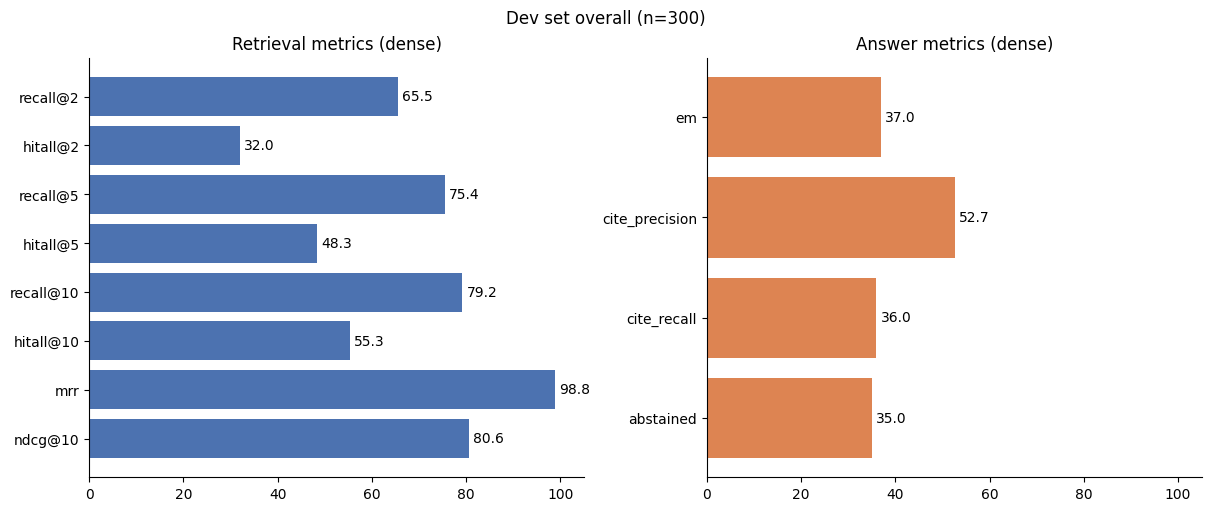

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
retr = {k: v for k, v in OVERALL.items() if k.startswith(("recall", "hitall")) or k in ("mrr", "ndcg@10")}
answ = {k: v for k, v in OVERALL.items() if k in ("em", "f1", "cite_precision", "cite_recall", "abstained")}
for ax, d, c, t in [(axes[0], retr, "#4C72B0", "Retrieval metrics (dense)"),
                    (axes[1], answ, "#DD8452", "Answer metrics (dense)")]:
    keys = list(d)[::-1]
    bars = ax.barh(keys, [d[k] for k in keys], color=c)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_xlim(0, 105); ax.set_title(t)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Dev set overall (n={OVERALL_N})")
fig.savefig("overall_metrics.png", dpi=200)
plt.show()

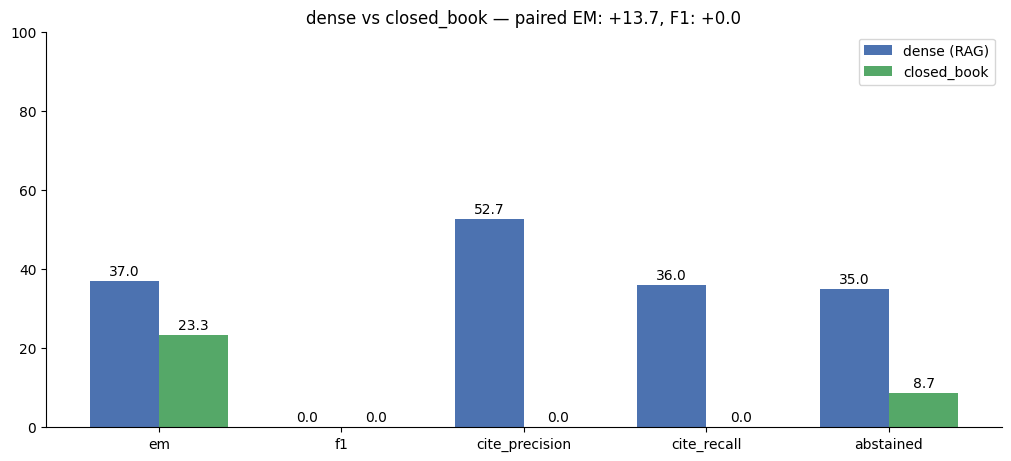

In [ ]:
metrics = ["em", "f1", "cite_precision", "cite_recall", "abstained"]
x = np.arange(len(metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
b1 = ax.bar(x - w/2, [OVERALL.get(m, 0.0) for m in metrics], w, label="dense (RAG)", color="#4C72B0")
b2 = ax.bar(x + w/2, [CLOSED_BOOK.get(m, 0.0) for m in metrics], w, label="closed_book", color="#55A868")
ax.bar_label(b1, fmt="%.1f", padding=2); ax.bar_label(b2, fmt="%.1f", padding=2)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 100); ax.legend()
if PAIRED:
    ax.set_title(f"dense vs closed_book — paired EM: {PAIRED.get('em', 0.0):+.1f}, F1: {PAIRED.get('f1', 0.0):+.1f}")
else:
    ax.set_title("dense vs closed_book")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("dense_vs_closedbook.png", dpi=200)
plt.show()

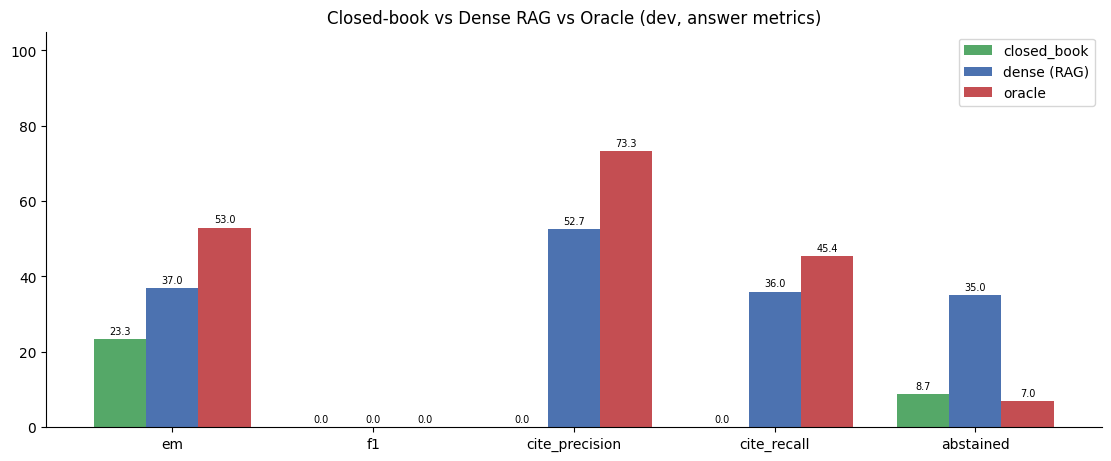

In [ ]:
metrics = ["em", "f1", "cite_precision", "cite_recall", "abstained"]
systems = [("closed_book", CLOSED_BOOK, "#55A868"),
           ("dense (RAG)", OVERALL, "#4C72B0"),
           ("oracle", ORACLE, "#C44E52")]
x = np.arange(len(metrics)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
for i, (label, vals, color) in enumerate(systems):
    bars = ax.bar(x + (i - 1) * w, [vals.get(m, 0.0) for m in metrics], w, label=label, color=color)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 105); ax.legend()
ax.set_title("Closed-book vs Dense RAG vs Oracle (dev, answer metrics)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("three_systems.png", dpi=200)
plt.show()

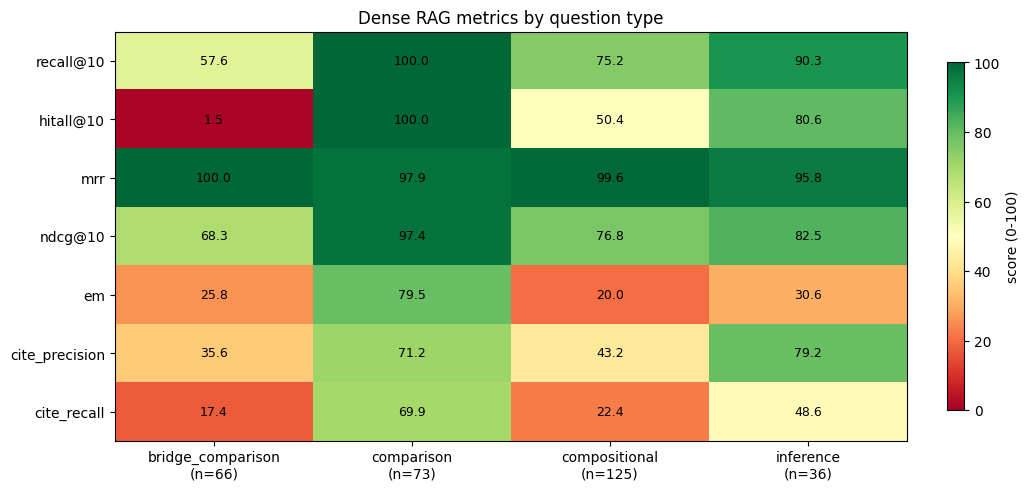

In [ ]:
TYPES = list(BY_TYPE)
METRICS = [m for m in ("recall@10", "hitall@10", "mrr", "ndcg@10", "em", "f1", "cite_precision", "cite_recall")
           if TYPES and all(m in BY_TYPE[t] for t in TYPES)]
if not TYPES or not METRICS:
    print("there is not any data for heatmap ")
else:
    M = np.array([[BY_TYPE[t][m] for t in TYPES] for m in METRICS])
    fig, ax = plt.subplots(figsize=(1.8 * len(TYPES) + 3, 4.8), constrained_layout=True)
    im = ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(TYPES)))
    ax.set_xticklabels([f"{t}\n(n={TYPE_N[t]})" for t in TYPES])
    ax.set_yticks(range(len(METRICS))); ax.set_yticklabels(METRICS)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9)
    ax.set_title("Dense RAG metrics by question type")
    fig.colorbar(im, ax=ax, shrink=0.85, label="score (0-100)")
    fig.savefig("metrics_by_type.png", dpi=200)
    plt.show()

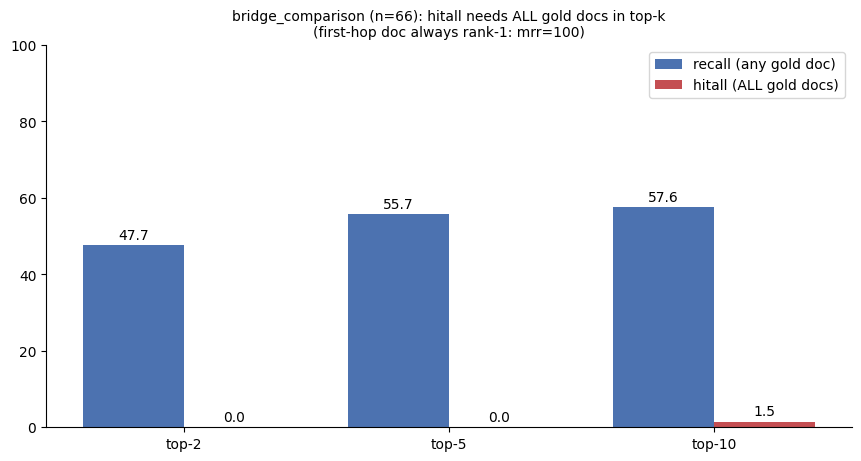

In [ ]:
bridge = next((t for t in BY_TYPE if "bridge" in t), None)
if bridge is None:
    print("type of bridge not found")
else:
    B = BY_TYPE[bridge]; ks = ["2", "5", "10"]
    x = np.arange(3); w = 0.38
    fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
    b1 = ax.bar(x - w/2, [B[f"recall@{k}"] for k in ks], w, label="recall (any gold doc)", color="#4C72B0")
    b2 = ax.bar(x + w/2, [B[f"hitall@{k}"] for k in ks], w, label="hitall (ALL gold docs)", color="#C44E52")
    ax.bar_label(b1, fmt="%.1f", padding=2); ax.bar_label(b2, fmt="%.1f", padding=2)
    ax.set_xticks(x); ax.set_xticklabels([f"top-{k}" for k in ks])
    ax.set_ylim(0, 100); ax.legend()
    ax.set_title(f"{bridge} (n={TYPE_N[bridge]}): hitall needs ALL gold docs in top-k\n(first-hop doc always rank-1: mrr={B.get('mrr', 0):.0f})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig("bridge_hitall_artifact.png", dpi=200)
    plt.show()

In [ ]:
STD_ID = "404722145"
GITHUB_URL = "https://github.com/mohammad-hossein-k-gh/Advanced-NLP_Phase1"
GITHUB_COMMIT = "YOUR_COMMIT_HASH"

EMBEDDING_MODEL_NAME = "Qwen/Qwen3-Embedding-4B"
LLM_MODEL_NAME = "Qwen/Qwen3-8B"

REPORT_PATH = OUTPUT_DIR / "report.pdf"

In [107]:
!pip install reportlab weasyprint -q

from pathlib import Path
import shutil
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    PageBreak, Image, KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
from xml.sax.saxutils import escape
from weasyprint import HTML

OUTPUT_DIR = Path("/kaggle/working/NLP_phase1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_NAMES = [
    "overall_metrics.png",
    "dense_vs_closedbook.png",
    "three_systems.png",
    "metrics_by_type.png",
    "bridge_hitall_artifact.png",
]

search_roots = [
    Path("/kaggle/working"),
    Path.cwd(),
    OUTPUT_DIR,
]

copied = {}
for name in FIGURE_NAMES:
    found = None
    for root in search_roots:
        cand = root / name
        if cand.exists():
            found = cand
            break
        hits = list(root.rglob(name))
        if hits:
            found = hits[0]
            break
    if found is None:
        print("MISSING:", name)
        continue
    dest = FIG_DIR / name
    if found.resolve() != dest.resolve():
        shutil.copy2(found, dest)
    copied[name] = dest
    print("OK:", name, "←", found)


def f(d, k, default="—"):
    if not isinstance(d, dict) or k not in d:
        return default
    v = d[k]
    return f"{v:.1f}" if isinstance(v, (int, float)) else str(v)


def gap(a, b, k):
    if k not in a or k not in b:
        return "—"
    return f"{a[k] - b[k]:+.1f}"


CLOSED_BOOK = {
    "em": 23.3, "f1": 31.5, "cite_precision": 0.0, "cite_recall": 0.0, "abstained": 8.7,
    "recall@2": 0.0, "recall@5": 0.0, "recall@10": 0.0,
    "hitall@2": 0.0, "hitall@5": 0.0, "hitall@10": 0.0,
    "mrr": 0.0, "ndcg@10": 0.0,
}
OVERALL = {
    "em": 37.0, "f1": 46.5, "cite_precision": 52.7, "cite_recall": 36.0, "abstained": 35.0,
    "recall@2": 65.5, "recall@5": 75.4, "recall@10": 79.2,
    "hitall@2": 32.0, "hitall@5": 48.3, "hitall@10": 55.3,
    "mrr": 98.8, "ndcg@10": 80.6,
}
ORACLE = {
    "em": 53.0, "f1": 66.4, "cite_precision": 73.3, "cite_recall": 45.4, "abstained": 7.0,
    "recall@2": 89.0, "recall@5": 100.0, "recall@10": 100.0,
    "hitall@2": 78.0, "hitall@5": 100.0, "hitall@10": 100.0,
    "mrr": 100.0, "ndcg@10": 100.0,
}
BY_TYPE = {
    "comparison": {
        "em": 79.5, "f1": 89.7, "recall@10": 100.0, "hitall@10": 100.0,
        "mrr": 97.9, "ndcg@10": 97.4, "abstained": 0.0,
        "recall@2": 90.4, "hitall@2": 80.8, "recall@5": 100.0, "hitall@5": 100.0,
    },
    "bridge_comparison": {
        "em": 25.8, "f1": 27.9, "recall@10": 57.6, "hitall@10": 1.5,
        "mrr": 100.0, "ndcg@10": 68.3, "abstained": 56.1,
        "recall@2": 47.7, "hitall@2": 0.0, "recall@5": 55.7, "hitall@5": 0.0,
    },
    "compositional": {
        "em": 20.0, "f1": 28.1, "recall@10": 75.2, "hitall@10": 50.4,
        "mrr": 99.6, "ndcg@10": 76.8, "abstained": 52.0,
        "recall@2": 61.6, "hitall@2": 23.2, "recall@5": 69.6, "hitall@5": 39.2,
    },
    "inference": {
        "em": 30.6, "f1": 56.8, "recall@10": 90.3, "hitall@10": 80.6,
        "mrr": 95.8, "ndcg@10": 82.5, "abstained": 8.3,
        "recall@2": 61.1, "hitall@2": 22.2, "recall@5": 81.9, "hitall@5": 63.9,
    },
}
TYPE_N = {
    "comparison": 73,
    "bridge_comparison": 66,
    "compositional": 125,
    "inference": 36,
}
PAIRED = {
    "em": 13.7, "f1": 15.0, "recall@10": 79.2, "hitall@10": 55.3,
}
type_order = ["comparison", "bridge_comparison", "compositional", "inference"]

cb = CLOSED_BOOK if "CLOSED_BOOK" in globals() else {}
dens = OVERALL if "OVERALL" in globals() else {}
ora = ORACLE if "ORACLE" in globals() else {}
by_type = BY_TYPE if "BY_TYPE" in globals() else {}
type_n = TYPE_N if "TYPE_N" in globals() else {}
paired = PAIRED if "PAIRED" in globals() else {}
n_dev = OVERALL_N if "OVERALL_N" in globals() else 300

STD_ID = "404722145"
GITHUB_URL = "https://github.com/mohammad-hossein-k-gh/Advanced-NLP_Phase1"
GITHUB_COMMIT = "YOUR_COMMIT_HASH"
EMBEDDING_MODEL = "Qwen/Qwen3-Embedding-4B"
LLM_MODEL = "Qwen/Qwen3-8B"


def fig_tag(name, caption):
    path = FIG_DIR / name
    if not path.exists():
        return f"<p class='note'>[نمودار موجود نیست: {name}]</p>"
    return f"""
    <div class="fig">
      <img src="{path.as_uri()}" alt="{caption}"/>
      <div class="cap">{caption}</div>
    </div>"""


def type_rows_fa():
    rows = ""
    for t in type_order:
        m = by_type.get(t, {})
        rows += f"""<tr>
          <td>{t}</td><td>{type_n.get(t,'')}</td>
          <td>{f(m,'em')}</td><td>{f(m,'f1')}</td>
          <td>{f(m,'recall@10')}</td><td>{f(m,'hitall@10')}</td>
          <td>{f(m,'mrr')}</td><td>{f(m,'ndcg@10')}</td><td>{f(m,'abstained')}</td>
        </tr>"""
    return rows


html = f"""
<!DOCTYPE html>
<html lang="fa" dir="rtl">
<head>
<meta charset="utf-8"/>
<style>
  @import url('https://cdn.jsdelivr.net/gh/rastikerdar/vazirmatn@v33.003/Vazirmatn-font-face.css');
  @page {{ size: A4; margin: 1.5cm; }}
  body {{ font-family: Vazirmatn, Tahoma, sans-serif; font-size: 10pt; line-height: 1.65; direction: rtl; text-align: justify; color:#222; }}
  h1 {{ font-size: 15pt; text-align: center; margin: 0 0 2px 0; }}
  h2 {{ font-size: 12pt; text-align: center; margin: 0 0 14px 0; color:#333; }}
  h3 {{ font-size: 11pt; border-bottom: 1px solid #ccc; padding-bottom: 3px; margin-top: 16px; }}
  h4 {{ font-size: 10pt; margin: 10px 0 4px 0; }}
  table.meta td {{ padding: 3px 6px; font-size: 9pt; }}
  table.meta td:first-child {{ font-weight: bold; width: 30%; }}
  table.data {{ width: 100%; border-collapse: collapse; margin: 8px 0 12px; font-size: 8pt; }}
  table.data th, table.data td {{ border: 1px solid #bbb; padding: 4px 3px; text-align: center; }}
  table.data th {{ background: #e8eaf0; }}
  table.data tr:nth-child(even) td {{ background: #f7f8fb; }}
  .en {{ direction: ltr; unicode-bidi: isolate; }}
  .example {{ background:#f8f9fc; border-right: 3px solid #6b7bb5; padding: 8px 10px; margin: 8px 0; font-size: 9pt; }}
  .fig {{ text-align: center; margin: 12px 0 16px 0; }}
  .fig img {{ max-width: 100%; height: auto; }}
  .cap {{ font-size: 8.5pt; color:#444; margin-top: 4px; font-style: italic; }}
  .note {{ font-size: 9pt; color:#666; }}
  .footer {{ margin-top: 20px; text-align: center; font-size: 9pt; color:#555; }}
  ul.compact {{ margin: 6px 0 10px 0; padding-right: 18px; }}
  ul.compact li {{ margin: 3px 0; }}
</style>
</head>
<body>
<p style="text-align:center; margin:0 0 6px 0;">بسم تعالی</p>
<h1>گزارش پروژه درس پردازش زبان طبیعی پیشرفته</h1>
<h2>فاز ۱ — سنجش بازیابی متراکم و پرسش‌وپاسخ چندگامی</h2>

<table class="meta">
  <tr><td>تهیه‌کننده</td><td>محمدحسین کریمی</td></tr>
  <tr><td>شماره دانشجویی</td><td>{STD_ID}</td></tr>
  <tr><td>مخزن GitHub</td><td class="en">{GITHUB_URL}</td></tr>
  <tr><td>شناسه Commit</td><td class="en">{GITHUB_COMMIT}</td></tr>
  <tr><td>مدل Embedding</td><td class="en">{EMBEDDING_MODEL}</td></tr>
  <tr><td>مدل تولید پاسخ</td><td class="en">{LLM_MODEL}</td></tr>
  <tr><td>سخت‌افزار</td><td>دو GPU از نوع Tesla T4 در محیط Kaggle، با دقت float16</td></tr>
  <tr><td>تاریخ</td><td class="en">2026-10-23</td></tr>
</table>

<h3>۱. معرفی سامانه‌ها و مدل‌ها</h3>
<p>
در این فاز سه سامانه روی پیکره‌ای با ۳۸۸۲ گذرگاه ارزیابی شده‌اند: سامانه بدون‌بازیابی (Closed-book) به‌عنوان کران پایین، RAG متراکم که پنج گذرگاه برتر را به مدل می‌دهد، و سامانه زمینه طلایی (Oracle) که فقط روی مجموعه توسعه اجرا می‌شود و نقش کران بالا را دارد.
بازیابی با مدل <span class="en">{EMBEDDING_MODEL}</span> انجام می‌شود. برای هر گذرگاه نمایش «عنوان / متن» ساخته می‌شود، سپس با pooling روی آخرین توکن و نرمال‌سازی L2، جست‌وجوی کامل کسینوسی روی کل پیکره اجرا می‌گردد. ده گذرگاه برتر ذخیره می‌شوند و پنج مورد اول برای تولید پاسخ به کار می‌روند.
پاسخ‌ها با مدل <span class="en">{LLM_MODEL}</span> و یک پرامپت صفر-نمونهٔ سخت‌گیرانه تولید می‌شوند: پاسخ باید کوتاه باشد، استناد به صورت <span class="en">[pXXXXX]</span> بیاید، و در صورت ناکافی بودن شواهد صریحاً امتناع شود. برای مهار تکرار، مقادیر
<span class="en">max_new_tokens=128</span>،
<span class="en">no_repeat_ngram_size=8</span>
و
<span class="en">repetition_penalty=1.05</span>
تنظیم شده‌اند.
ارزیابی با اسکریپت رسمی <span class="en">score.py</span> روی مجموعه توسعه (n={n_dev}) انجام شده و فاصله اطمینان ۹۵٪ با بوت‌استرپ روی پرسش‌ها گزارش شده است.
</p>
<table class="data">
  <tr><th>سامانه</th><th>زمینه</th><th>نقش</th></tr>
  <tr><td>Closed-book (بدون‌بازیابی)</td><td>بدون زمینه</td><td>کران پایین</td></tr>
  <tr><td>Dense RAG (متراکم)</td><td>پنج گذرگاه برتر</td><td>خط لوله اصلی</td></tr>
  <tr><td>Oracle (زمینه طلایی)</td><td>اسناد طلایی</td><td>کران بالا روی dev</td></tr>
</table>

<h3>۲. نتایج کلی روی مجموعه توسعه</h3>
<p><b>معیارهای پاسخ:</b></p>
<table class="data">
  <tr><th>سامانه</th><th>EM</th><th>F1</th><th>Cite-P</th><th>Cite-R</th><th>Abstained</th></tr>
  <tr><td>Closed-book</td><td>{f(cb,'em')}</td><td>{f(cb,'f1')}</td><td>{f(cb,'cite_precision')}</td><td>{f(cb,'cite_recall')}</td><td>{f(cb,'abstained')}</td></tr>
  <tr><td>Dense RAG</td><td>{f(dens,'em')}</td><td>{f(dens,'f1')}</td><td>{f(dens,'cite_precision')}</td><td>{f(dens,'cite_recall')}</td><td>{f(dens,'abstained')}</td></tr>
  <tr><td>Oracle</td><td>{f(ora,'em')}</td><td>{f(ora,'f1')}</td><td>{f(ora,'cite_precision')}</td><td>{f(ora,'cite_recall')}</td><td>{f(ora,'abstained')}</td></tr>
</table>
<p class="note">اعداد به درصد هستند و فاصله اطمینان ۹۵٪ بوت‌استرپ در متن کامل گزارش آمده است؛ برای نمونه، در سامانه متراکم EM برابر ۳۷٫۰ با بازه [۳۱٫۷، ۴۳٫۰] است.</p>
{fig_tag("three_systems.png", "شکل ۱. مقایسه سه سامانه روی معیارهای پاسخ (مجموعه توسعه)")}

<p><b>معیارهای بازیابی:</b></p>
<table class="data">
  <tr><th>سامانه</th><th>R@2</th><th>R@5</th><th>R@10</th><th>H@2</th><th>H@5</th><th>H@10</th><th>MRR</th><th>nDCG@10</th></tr>
  <tr><td>Closed-book</td><td>{f(cb,'recall@2')}</td><td>{f(cb,'recall@5')}</td><td>{f(cb,'recall@10')}</td><td>{f(cb,'hitall@2')}</td><td>{f(cb,'hitall@5')}</td><td>{f(cb,'hitall@10')}</td><td>{f(cb,'mrr')}</td><td>{f(cb,'ndcg@10')}</td></tr>
  <tr><td>Dense RAG</td><td>{f(dens,'recall@2')}</td><td>{f(dens,'recall@5')}</td><td>{f(dens,'recall@10')}</td><td>{f(dens,'hitall@2')}</td><td>{f(dens,'hitall@5')}</td><td>{f(dens,'hitall@10')}</td><td>{f(dens,'mrr')}</td><td>{f(dens,'ndcg@10')}</td></tr>
  <tr><td>Oracle</td><td>{f(ora,'recall@2')}</td><td>{f(ora,'recall@5')}</td><td>{f(ora,'recall@10')}</td><td>{f(ora,'hitall@2')}</td><td>{f(ora,'hitall@5')}</td><td>{f(ora,'hitall@10')}</td><td>{f(ora,'mrr')}</td><td>{f(ora,'ndcg@10')}</td></tr>
</table>
{fig_tag("overall_metrics.png", "شکل ۲. معیارهای کلی سامانه متراکم از خروجی score.py")}

<p>
عرض فاصله اطمینان برای R@2 در کل داده حدود ±۲٫۷ و برای EM حدود ±۵٫۷ است؛ در زیرگروه‌های کوچک‌تر، مانند پرسش‌های استنتاجی با ۳۶ نمونه، این بازه تا حدود ±۱۶ هم می‌رسد.
معیار HitAll نشان می‌دهد که آیا همه اسناد طلایی در k نتیجه اول حضور دارند یا نه.
الگوی نتایج روشن است: MRR سامانه متراکم به {f(dens,'mrr')} می‌رسد و یعنی سند مرتبط اول تقریباً همیشه در رتبه یک قرار می‌گیرد، اما HitAll@10 تنها {f(dens,'hitall@10')} است. به بیان دیگر، در نزدیک نیمی از پرسش‌ها مجموعه کامل اسناد طلایی بازیابی نمی‌شود.
مقدار EM از {f(cb,'em')} در حالت بدون‌بازیابی به {f(dens,'em')} با RAG و سپس به {f(ora,'em')} با زمینه طلایی افزایش می‌یابد.
</p>

<h3>۳. نتایج به تفکیک نوع پرسش</h3>
<p>اعداد زیر مربوط به سامانه RAG متراکم هستند.</p>
{fig_tag("metrics_by_type.png", "شکل ۳. نقشه حرارتی معیارهای سامانه متراکم به تفکیک نوع پرسش")}
<table class="data">
  <tr><th>type</th><th>n</th><th>EM</th><th>F1</th><th>R@10</th><th>H@10</th><th>MRR</th><th>nDCG@10</th><th>Abs.</th></tr>
  {type_rows_fa()}
</table>

<p>
پرسش‌های مقایسه‌ای آسان‌ترین گروه هستند (EM برابر ۷۹٫۵ و R@2 برابر ۹۰٫۴)، چون معمولاً هر دو سند مربوط به موجودیت‌ها در رتبه‌های نخست ظاهر می‌شوند.
در مقابل، پرسش‌های پل‌زنی سخت‌ترین گروه به شمار می‌روند: HitAll@5 دقیقاً صفر و HitAll@10 فقط ۱٫۵ است. دلیل اصلی آن است که به‌طور میانگین چهار سند طلایی لازم است و سند واسط — اغلب زندگی‌نامه کارگردان — به‌ندرت در میان نتایج برتر می‌آید.
نکته قابل توجه این است که در همین گروه، EM سامانه بدون‌بازیابی (۴۲٫۴) از RAG متراکم (۲۵٫۸) بالاتر است؛ زیرا RAG در ۵۶٫۱ درصد موارد به‌خاطر ناکافی بودن شواهد خودداری می‌کند و پاسخ خودداری امتیاز EM نمی‌گیرد.
</p>
<p><b>مقایسه EM سه سامانه به تفکیک نوع پرسش:</b></p>
<ul class="compact">
  <li>مقایسه‌ای (n=۷۳): بدون‌بازیابی ۴۵٫۲ [۳۴٫۲، ۵۶٫۲]؛ متراکم ۷۹٫۵ [۶۹٫۹، ۸۹٫۰]؛ طلایی ۷۶٫۷ [۶۷٫۱، ۸۶٫۳]</li>
  <li>پل‌زنی (n=۶۶): بدون‌بازیابی ۴۲٫۴ [۳۰٫۳، ۵۴٫۵]؛ متراکم ۲۵٫۸ [۱۵٫۲، ۳۴٫۸]؛ طلایی ۵۰٫۰ [۳۹٫۴، ۶۲٫۱]</li>
  <li>ترکیبی (n=۱۲۵): بدون‌بازیابی ۷٫۲ [۳٫۲، ۱۲٫۰]؛ متراکم ۲۰٫۰ [۱۳٫۶، ۲۷٫۲]؛ طلایی ۴۳٫۲ [۳۴٫۴، ۵۲٫۰]</li>
  <li>استنتاجی (n=۳۶): بدون‌بازیابی ۰٫۰؛ متراکم ۳۰٫۶ [۱۳٫۹، ۴۷٫۲]؛ طلایی ۴۴٫۴ [۲۷٫۸، ۶۱٫۱]</li>
</ul>

<h3>۴. ادعاهای مقایسه‌ای بر اساس تفاضل جفتی</h3>
{fig_tag("dense_vs_closedbook.png", "شکل ۴. مقایسه جفتی RAG متراکم و سامانه بدون‌بازیابی")}
<table class="data">
  <tr><th>معیار</th><th>Dense − Closed-book</th><th>Oracle − Dense</th></tr>
  <tr><td>EM</td><td>+13.7 [+7.7, +20.0]</td><td>+16.0 [+10.7, +21.3]</td></tr>
  <tr><td>F1</td><td>+15.0 [+8.9, +21.3]</td><td>+19.9 [+14.6, +25.1]</td></tr>
  <tr><td>Recall@2</td><td>+65.5 [+62.6, +68.0]</td><td>+23.5 [+20.8, +26.2]</td></tr>
  <tr><td>HitAll@2</td><td>+32.0 [+26.3, +37.0]</td><td>+46.0 [+40.7, +51.7]</td></tr>
  <tr><td>Recall@10</td><td>+79.2 [+76.5, +81.7]</td><td>+20.8 [+18.3, +23.5]</td></tr>
  <tr><td>HitAll@10</td><td>+55.3 [+49.3, +60.7]</td><td>+44.7 [+39.3, +50.7]</td></tr>
  <tr><td>MRR</td><td>+98.8 [+98.0, +99.7]</td><td>+1.2 [+0.3, +2.0]</td></tr>
  <tr><td>nDCG@10</td><td>+80.6 [+78.7, +82.4]</td><td>+19.4 [+17.6, +21.3]</td></tr>
  <tr><td>Cite-P</td><td>+52.7 [+47.0, +58.5]</td><td>+20.7 [+13.7, +27.5]</td></tr>
  <tr><td>Cite-R</td><td>+36.0 [+31.6, +40.4]</td><td>+9.4 [+4.5, +14.1]</td></tr>
  <tr><td>نرخ خودداری</td><td>+26.3 [+20.3, +32.7]</td><td>−28.0 [−33.7, −22.7]</td></tr>
</table>
<p>
از این اعداد چند نتیجه روشن به دست می‌آید.
نخست، RAG متراکم نسبت به حالت بدون‌بازیابی برتری معنادار دارد: افزایش EM برابر ۱۳٫۷ و افزایش F1 برابر ۱۵٫۰ است و کف فاصله اطمینان در هر دو مورد بالای صفر قرار دارد.
دوم، برتری در بازیابی تقریباً مطلق است؛ زیرا بازیابی سامانه بدون‌بازیابی به‌تعریف صفر است و در نتیجه R@10 به ۷۹٫۲ و MRR به ۹۸٫۸ می‌رسد.
سوم، زمینه طلایی همچنان از RAG متراکم جلوتر است: EM حدود ۱۶ واحد و HitAll@10 حدود ۴۴٫۷ واحد بالاتر. این فاصله همان «فاصله تا سقف» با بازیابی کامل است.
چهارم، نرخ خودداری تابع کامل بودن شواهد است. سامانه متراکم نسبت به بدون‌بازیابی ۲۶٫۳ واحد بیشتر خودداری می‌کند، اما با اسناد طلایی ۲۸ واحد کمتر. بنابراین خودداری بیشتر عمدتاً نتیجه ناقص بودن بازیابی است، نه صرفاً سخت‌گیری پرامپت.
پنجم، حتی با اسناد کامل، EM به حدود ۵۳ درصد می‌رسد و خطای باقی‌مانده بیشتر قالبی یا مربوط به ناهمخوانی لفظی پاسخ با مرجع است.
</p>

<h3>۵. شکاف میان recall و HitAll در پرسش‌های پل‌زنی</h3>
{fig_tag("bridge_hitall_artifact.png", "شکل ۵. در پرسش‌های پل‌زنی، recall می‌تواند بالا باشد اما HitAll نزدیک صفر بماند")}
<p>
در پرسش‌های پل‌زنی معمولاً سند مرتبط اول در رتبه یک قرار می‌گیرد و به همین دلیل MRR بالاست؛ اما سند دوم یا سند واسط در میان نتایج برتر نیست و در نتیجه HitAll نزدیک صفر می‌ماند. این همان گلوگاه اصلی بازیابی چندگامی است.
در کل مجموعه توسعه، ۱۳۴ پرسش از ۳۰۰ پرسش (۴۴٫۷ درصد) HitAll@10 برابر صفر دارند و در ۶۲ مورد پاسخ اوراکل درست بوده، در حالی که پاسخ RAG متراکم نادرست یا خودداری بوده است.
</p>

<h3>۶. تحلیل خطا</h3>
<div class="example"><b>ناتمامی مجموعه اسناد طلایی (رایج‌ترین خطا):</b> در پرسش‌های پل‌زنی به‌طور میانگین چهار سند لازم است. سند نخست تقریباً همیشه رتبه یک را می‌گیرد، اما سند واسط یا سند دوم از دست می‌رود و HitAll@5 صفر می‌شود. نمونه‌های مشخص در پیوست آمده‌اند.</div>
<div class="example"><b>خودداری بیش از حد با وجود شواهد کافی:</b> نرخ خودداری کل سامانه متراکم {f(dens,'abstained')} درصد است (ترکیبی ۵۲٫۰ و پل‌زنی ۵۶٫۱)، در حالی که در اوراکل تنها {f(ora,'abstained')} درصد است. در نمونه q0013 هر دو سند طلایی در top-5 بوده‌اند، اما سامانه باز هم امتناع کرده است.</div>
<div class="example"><b>خطای تولید با شواهد کامل:</b> در نمونه q0010 هر دو سند طلایی در رتبه‌های یک و دو بوده‌اند، اما سامانه به‌جای «Georgetown, Kentucky» عبارت «Greenwich, Kentucky» را تولید کرده است؛ یعنی تداخل دو مکان هم‌شبیه در متن.</div>
<div class="example"><b>خطای قالبی و استنادی:</b> حتی با زمینه طلایی، EM برابر {f(ora,'em')} می‌ماند. بخشی از این فاصله به ناهمخوانی لفظی پاسخ با مرجع و بخشی به کاستی در استناد برمی‌گردد.</div>

<h3>۷. تصمیم‌های طراحی و محدودیت‌ها</h3>
<p>
چون پیکره فقط ۳۸۸۲ گذرگاه دارد، جست‌وجوی کامل کسینوسی به‌جای شاخص تقریبی انتخاب شد تا بازیابی دقیق ممکن باشد. به همین دلیل در این فاز از reranker استفاده نشد؛ هرچند نتایج HitAll نشان می‌دهد رتبه‌بندی سند دوم و سند واسط هنوز گلوگاه اصلی است و افزودن cross-encoder یا جست‌وجوی چندکوئری (پرسش به‌همراه نام موجودیت‌ها) می‌تواند گام بعدی مفیدی باشد.
پرامپت سخت‌گیرانه و قاعده امتناع برای کاهش توهم انتخاب شد؛ هزینه این انتخاب نرخ خودداری {f(dens,'abstained')} درصدی در RAG است که EM را در گروه‌های با شواهد ناقص پایین می‌آورد.
محدودیت‌های اصلی عبارت‌اند از: استفاده از دو GPU از نوع T4 با دقت float16، جست‌وجوی محدود ابرپارامترها، به‌کارگیری یک خانواده مدل (Qwen3) برای هر دو نقش embedding و تولید، در دسترس نبودن برچسب‌های مجموعه پنهان برای ارزیابی محلی، و محدود بودن تحلیل کیفی خطا به نمونه‌های منتخب پیوست.
</p>

<h3>۸. شفافیت درباره ابزارهای هوش مصنوعی</h3>
<p>
در مراحل کدنویسی و ساختاردهی گزارش از GLM، Grok و GPT استفاده شده است.  .
</p>

<div class="footer">
مخزن: <span class="en">{GITHUB_URL}</span><br/>
Commit: <span class="en">{GITHUB_COMMIT}</span>
</div>

<h3>پیوست — پنج نمونه مشخص از خطاها</h3>
<div class="example">
<b>q0002 (پل‌زنی):</b> کارگردان کدام فیلم (The Third Side of the River یا Escape From L.A.) دیرتر متولد شده است؟
پاسخ مرجع: The Third Side of the River. پاسخ سامانه متراکم: خودداری.
وضعیت بازیابی در top-10: p03489 رتبه ۱ و p01066 رتبه ۲؛ p00620 و p01750 خارج از top-10 (۲ از ۴).
علت: گم شدن دو سند طلایی در مسیر چندگامی و اعمال قاعده امتناع.
</div>
<div class="example">
<b>q0005 (ترکیبی):</b> چرا اجراکننده آهنگ Mermaid's Avenue درگذشته است؟
پاسخ مرجع: Huntington's disease. پاسخ سامانه متراکم: خودداری.
وضعیت بازیابی: p02340 رتبه ۱؛ p03814 که علت مرگ را دارد خارج از top-10 (۱ از ۲).
علت: گم شدن سند دوم طلایی.
</div>
<div class="example">
<b>q0012 (پل‌زنی):</b> کارگردان کدام فیلم (School on Fire یا Mark of the Frog) دیرتر درگذشته است؟
پاسخ مرجع: School on Fire. پاسخ سامانه متراکم: خودداری.
وضعیت بازیابی: p02270 رتبه ۱، p03047 رتبه ۲، p02920 رتبه ۹؛ p00311 خارج (۳ از ۴).
علت: ناتمام بودن مجموعه طلایی؛ پاسخ در سند گم‌شده بوده است.
</div>
<div class="example">
<b>q0010 (ترکیبی):</b> پدر Isaac B. Desha کجا درگذشته است؟
پاسخ مرجع: Georgetown, Kentucky. پاسخ سامانه متراکم: Greenwich, Kentucky.
وضعیت بازیابی: هر دو سند طلایی در رتبه‌های ۱ و ۲ (۲ از ۲).
علت: خطای تولید؛ تداخل دو مکان هم‌شبیه با وجود شواهد کامل.
</div>
<div class="example">
<b>q0013 (ترکیبی):</b> محل درگذشت آهنگساز How Long Has This Been Going On? کجاست؟
پاسخ مرجع: Hollywood. پاسخ سامانه متراکم: خودداری.
وضعیت بازیابی: هر دو سند طلایی در top-5؛ p01543 رتبه ۱ و p01270 رتبه ۴ (۲ از ۲).
علت: خودداری بیش از حد با وجود شواهد کافی.
</div>
<p class="note">
نمونه‌های مشابه دیگری نیز دیده می‌شود؛ از جمله q0014 (ترکیبی؛ سند دوم p03653 خارج از top-10) و q0015 و q0017 با الگوی ناتمامی مجموعه طلایی یا امتناع.
در همه نمونه‌های پیوست، شناسه پرسش، پاسخ سامانه، پاسخ مرجع، وضعیت قطعات بازیابی‌شده و علت خطا مشخص شده است.
</p>
</body></html>
"""

REPORT_FA = OUTPUT_DIR / "report_fa.pdf"
HTML(string=html, base_url=str(OUTPUT_DIR)).write_pdf(str(REPORT_FA))
print("Wrote:", REPORT_FA)

REPORT_PATH = OUTPUT_DIR / "report.pdf"
shutil.copy2(REPORT_FA, REPORT_PATH)
print("Copied submission report →", REPORT_PATH)

OK: overall_metrics.png ← /kaggle/working/overall_metrics.png
OK: dense_vs_closedbook.png ← /kaggle/working/dense_vs_closedbook.png
OK: three_systems.png ← /kaggle/working/three_systems.png
OK: metrics_by_type.png ← /kaggle/working/metrics_by_type.png
OK: bridge_hitall_artifact.png ← /kaggle/working/bridge_hitall_artifact.png
Wrote: /kaggle/working/NLP_phase1/report_fa.pdf
Copied submission report → /kaggle/working/NLP_phase1/report.pdf


In [108]:

import json
import zipfile
from pathlib import Path

STD_ID = "404722145"
SUBMISSION_ZIP = Path("/kaggle/working") / f"P1_{STD_ID}.zip"
REPORT_PATH = OUTPUT_DIR / "report.pdf"   

required_run_dirs = [
    RUN_PATHS["closed_book"],
    RUN_PATHS["oracle_context"],
    RUN_PATHS["dense_rag"],
    RUN_PATHS["hidden_closed_book"],
    RUN_PATHS["hidden_dense_rag"],
]
selfcheck_dir = OUTPUT_DIR / "runs" / "selfcheck"
all_dirs = required_run_dirs + [selfcheck_dir]
expected_counts = [300, 300, 300, 300, 300, 50]


EXPECTED_FIELDS = {"qid", "answer", "retrieved", "cited", "abstained"}

assert REPORT_PATH.exists(), f"report not found: {REPORT_PATH}"
for run_dir, n_exp in zip(all_dirs, expected_counts):
    pred = run_dir / "predictions.jsonl"
    assert pred.exists(), f"predictions not found: {pred}"
    with pred.open(encoding="utf-8") as fh:
        first = json.loads(fh.readline())
    assert set(first.keys()) == EXPECTED_FIELDS, (
        f"{pred}: the fild should exactly {sorted(EXPECTED_FIELDS)}: {sorted(first.keys())}"
    )
    n = sum(1 for line in pred.open(encoding="utf-8") if line.strip())
    assert n == n_exp, f"{pred}: {n} record — expect {n_exp}"


with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(REPORT_PATH, arcname="report.pdf")
    for run_dir in all_dirs:
        for fp in sorted(run_dir.rglob("*")):
            if fp.is_file():
                zf.write(fp, arcname=str(fp.relative_to(OUTPUT_DIR)))


with zipfile.ZipFile(SUBMISSION_ZIP) as zf:
    names = zf.namelist()
    print("ZIP contents:")
    for name in sorted(names):
        print("  ", name)
    assert "report.pdf" in names, "report.pdf not in ZIP "
    n_pred = sum(name.endswith("predictions.jsonl") for name in names)
    assert n_pred == 6, f"should 6 predictions.jsonl  (5 run + selfcheck) — now {n_pred}"

print("\nSubmission ZIP:", SUBMISSION_ZIP)
print("ZIP size (MB):", round(SUBMISSION_ZIP.stat().st_size / (1024**2), 2))

ZIP contents:
   report.pdf
   runs/dev/closed_book/predictions.jsonl
   runs/dev/closed_book/run_config.yaml
   runs/dev/dense/predictions.jsonl
   runs/dev/dense/run_config.yaml
   runs/dev/oracle/predictions.jsonl
   runs/dev/oracle/run_config.yaml
   runs/hidden/closed_book/predictions.jsonl
   runs/hidden/closed_book/run_config.yaml
   runs/hidden/dense/predictions.jsonl
   runs/hidden/dense/run_config.yaml
   runs/selfcheck/predictions.jsonl

Submission ZIP: /kaggle/working/P1_404722145.zip
ZIP size (MB): 0.39
